# Online Retail II - customer and revenue analysis

Analysis of the sales cleaned in MySQL (`retail_export.csv`): 1,001,903
purchase lines, 1 Dec 2009 - 9 Dec 2011, returns already offset against
the purchases. Discussion and limitations are in `report/REPORT.pdf`.

1. Load and check against SQL
2. Cohort retention and seasonality
3. Revenue concentration and persistence of the top customers
4. Customer segments (own k-medoids, `kmedoids.py`)
5. Customer actions, backtest, `output/customer_segments.csv`
6. Price bands, catalogue renewal, product actions, `output/product_actions.csv`

Customer analyses use known customers and product codes only: 5,839
customers, £16.41M.

### Loading the data

SQL export with explicit column types (`customer_id` is the only column
with missing values); descriptions from `products.csv`, one per stock code.

In [1]:
import py_utils as pu
from kmedoids import mean_dist_to_clusters, silhouette_samples, silhouette_vs, silhouette, kmedoids
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import cdist

data_dir, fig_dir, out_dir, csv_file = pu.directories("../data",
                                                      "../figures",
                                                      "../output",
                                                      "retail_export.csv")

# csv to df
retail_df = pd.read_csv(
    csv_file,
    dtype={
        "invoice": str,
        "stock_code": str,
        "is_product": "int8",
        "quantity": "int64",
        "price": "float64",
        "revenue": "float64",
        "customer_id": "Int64",
        "customer_key": str,
        "is_missing_customer": "int8",
    },
    parse_dates=["invoice_date"],
    keep_default_na=False,
    na_values={"customer_id": [""]},
)

pu.print_df(retail_df)

# One description per stock code (the most frequent one, chosen in SQL).
# Descriptions can contain commas and quotes, escaped with a backslash.
description = pd.read_csv(data_dir/"products.csv", escapechar="\\",
                          dtype={"stock_code": str}, keep_default_na=False,
                          index_col="stock_code")["description"]

Clean retail data:
(1001903, 10)
invoice                           str
stock_code                        str
is_product                       int8
quantity                        int64
invoice_date           datetime64[us]
price                         float64
revenue                       float64
customer_id                     Int64
customer_key                      str
is_missing_customer              int8
dtype: object


,invoice,stock_code,is_product,quantity,invoice_date,price,revenue,customer_id,customer_key,is_missing_customer
585401,545657,22630,1,12,2011-03-04,1.95,23.40,14911,14911,0
351581,525059,22482,1,12,2010-10-03,1.25,15.00,15978,15978,0
111381,500472,84978,1,1,2010-03-08,2.51,2.51,<NA>,MISSING-500472,1
635634,550499,22161,1,1,2011-04-18,0.79,0.79,<NA>,MISSING-550499,1
456666,534362,21452,1,2,2010-11-22,2.95,5.90,16200,16200,0
569268,544211,22150,1,6,2011-02-17,1.95,11.70,13018,13018,0
905843,574678,21668,1,12,2011-11-06,1.45,17.40,13365,13365,0
750334,561513,23182,1,2,2011-07-27,2.46,4.92,<NA>,MISSING-561513,1
285345,518613,20725,1,2,2010-08-10,1.65,3.30,16713,16713,0
526058,540468,84510A,1,5,2011-01-07,2.51,12.55,<NA>,MISSING-540468,1


### Checks against SQL

- Every figure matches the SQL results: 1,001,903 rows, £19,727,380.03
  revenue, £18,984,181.36 product revenue, 39,750 invoices, 5,859 known
  customers, 228,487 rows without customer (15.7% of revenue).
- No missing values outside `customer_id`; dates 1 Dec 2009 - 9 Dec 2011.

In [2]:
# Product lines only. Years run from December to November (Dec 2010 - Nov
# 2011 is 2011), so that each one contains a full Christmas season
sales = retail_df[retail_df["is_product"] == 1].assign(
    year=lambda d: d["invoice_date"].dt.year + (d["invoice_date"].dt.month == 12))
is_known = retail_df["is_missing_customer"] == 0
sales_with_cust = sales[sales["is_missing_customer"] == 0]     # known customers
sales_no_id = sales[sales["is_missing_customer"] == 1]         # without customer ID
two_years = sales[sales["year"].isin([2010, 2011])]            # Dec 2009 - Nov 2011
last_day = retail_df["invoice_date"].max()
ref_day = last_day + pd.Timedelta(days=1)                      # recency is counted from here
data_end = last_day.normalize() + pd.Timedelta(days=1)         # 10 Dec 2011, end of the data
rev_tot = retail_df["revenue"].sum()
rev_miss = retail_df.loc[~is_known, "revenue"].sum()

display(pd.Series({
    "Rows": len(retail_df),
    "Total revenue": round(rev_tot, 2),
    "Product revenue": round(sales["revenue"].sum(), 2),
    "Distinct invoices": retail_df["invoice"].nunique(),
    "Known customers": retail_df.loc[is_known, "customer_id"].nunique(),
    "Rows without customer": (~is_known).sum(),
    "% revenue without customer": round(100*rev_miss/rev_tot, 1),
    "No missing values outside customer_id":
        retail_df.drop(columns="customer_id").isna().sum().sum() == 0,
    "First date": f"{retail_df['invoice_date'].min():%Y-%m-%d}",
    "Last date": f"{last_day:%Y-%m-%d}",
}, name="value").to_frame())

,value
Rows,1001903
Total revenue,19727380.03
Product revenue,18984181.36
Distinct invoices,39750
Known customers,5859
Rows without customer,228487
% revenue without customer,15.7
No missing values outside customer_id,True
First date,2009-12-01
Last date,2011-12-09


### Cohort retention

Known customers, products only, grouped by month of first purchase;
averages weighted by cohort size. The December 2009 cohort (951 customers,
new and old mixed) and December 2011 (incomplete) are excluded.

- About 21% of new customers buy again the next month, about 18% are active
  12 months later.
- "New" means new to these data: later cohorts include returning old
  customers (about 250–440 a month in the first half of 2010, against
  100–220 in 2011).

In [3]:
# Known customers, products only. December 2011 is excluded.
known_two_years = two_years[two_years["is_missing_customer"] == 0]
active_cust = pu.cohort_activity(known_two_years)
first_cohort_size = active_cust.iloc[0, 0]  # Dec 2009, excluded
active_cust = active_cust.iloc[1:]

# Retention structures
ret_matr, avg_ret, n_cohorts, cohort_size = pu.retention_tables(active_cust)

# Printing avg retention infos
display_cols = [1, 3, 6, 9, 12, 15, 18, 21]
print("First cohort (Dec 2009, excluded) size:", first_cohort_size)
# New customers per cohort, one row per year
sizes = cohort_size.rename("new customers").to_frame()
display(sizes.set_index([sizes.index.str[:4], sizes.index.str[5:]])["new customers"]
        .unstack().astype("Int64").rename_axis(index="year", columns="month"))
display(pd.DataFrame({"avg_retention_pct": round(avg_ret[display_cols], 1),
                      "cohorts": n_cohorts[display_cols]}))

First cohort (Dec 2009, excluded) size: 951


month,01,02,03,04,05,06,07,08,09,10,11,12
year,,,,,,,,,,,,
2010,366,373,441,294,253,267,187,162,235,369,328,77
2011,73,126,178,106,113,108,101,108,185,221,190,<NA>


,avg_retention_pct,cohorts
period,,
1,20.9,22
3,21.1,20
6,18.4,17
9,15.0,14
12,18.4,11
15,16.3,8
18,17.0,5
21,18.3,2


Heatmap: share of each cohort active in every month after the first purchase.

- Retention follows the calendar: the darkest diagonals fall in
  September–November for every cohort, the lightest in December–February.
- Hence the average curve rises again at month 12.
- Acquisitions also peak in October–November and drop to about 75 a month
  in December–January.

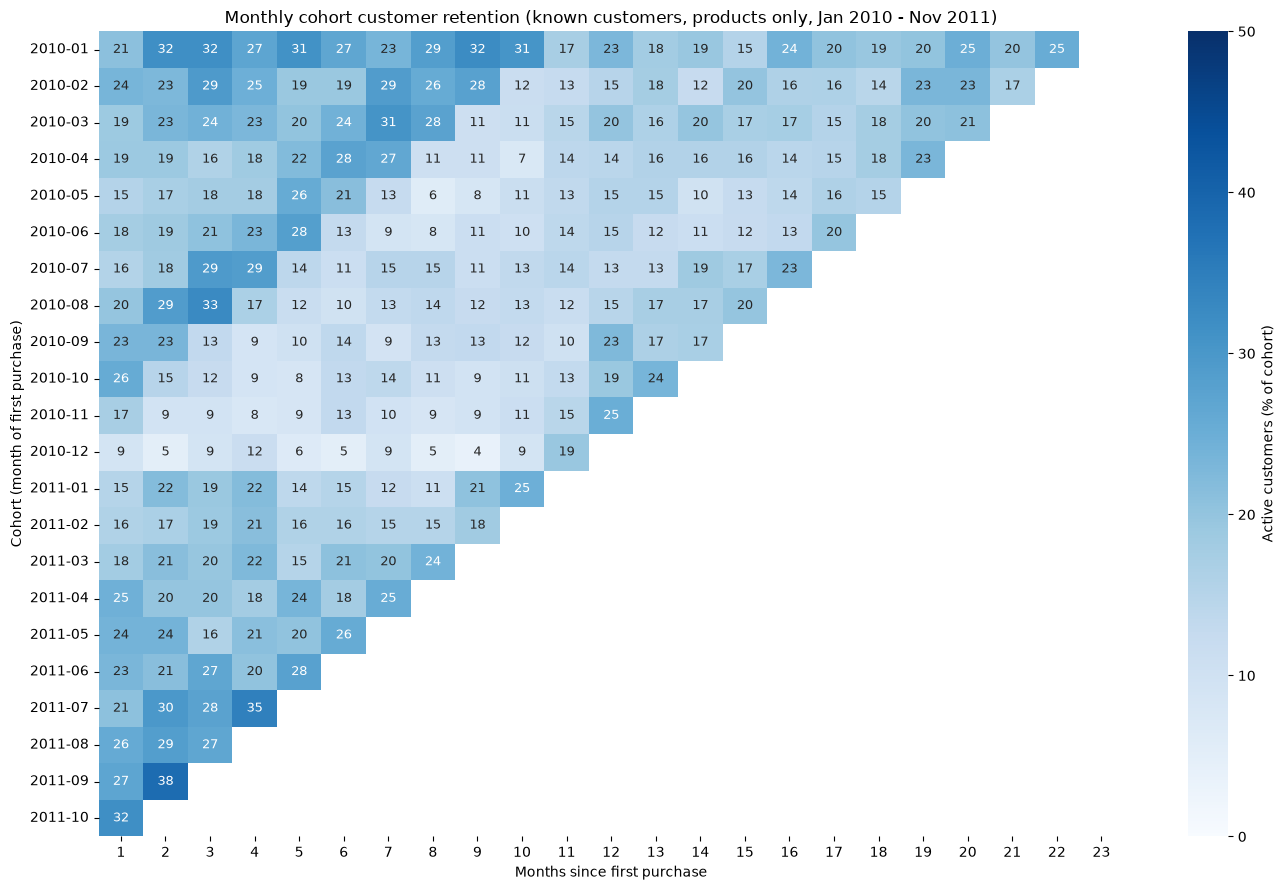

In [4]:
fig, ax = plt.subplots(figsize=(14, 9))
sns.heatmap(ret_matr.iloc[:-1, 1:], annot=True, fmt=".0f", cmap="Blues",
            vmin=0, vmax=50, cbar_kws={"label": "Active customers (% of cohort)"},
            annot_kws={"fontsize": 9}, ax=ax)
ax.tick_params(labelsize=10)
ax.set_xlabel("Months since first purchase")
ax.set_ylabel("Cohort (month of first purchase)")
ax.set_title(
    "Monthly cohort customer retention (known customers, products only, Jan 2010 - Nov 2011)")
pu.save_show_graph(fig, fig_dir, "cohort_retention.png")

### Seasonality

Weekly revenue of all product lines (with and without customer ID),
1 Jan 2010 – 31 Aug 2011. Peak months September–January fixed beforehand
from the cohorts, not from the fit.

First the weekly series as it is: autumn peaks in 2010 and 2011; the almost
empty week at the turn of 2010 – 2011 is the Christmas closure.

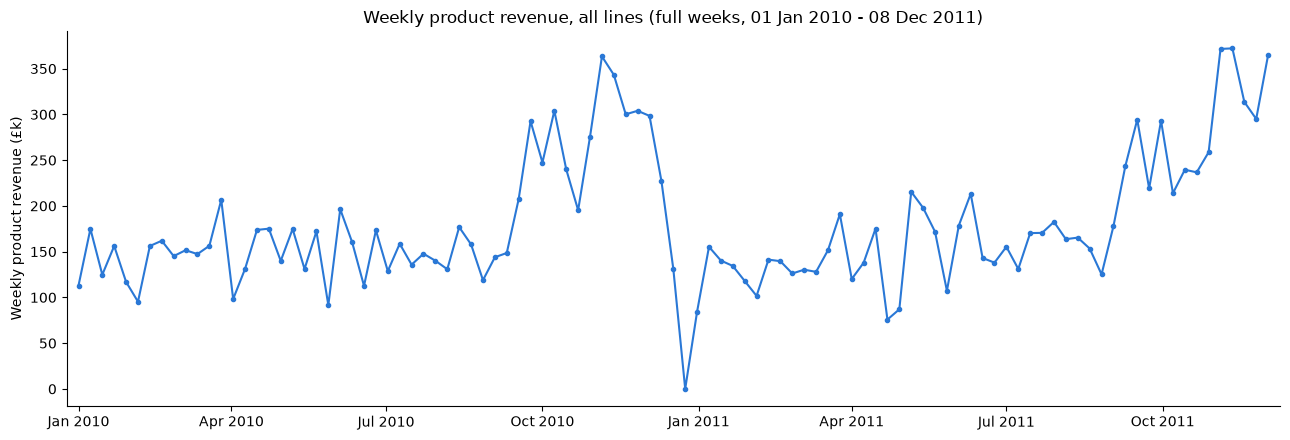

In [5]:
# Weekly product revenue of all lines (also without customer ID): this is the
# seasonality of the business, not of known customers. Window: 1 Jan 2010 -
# 31 Aug 2011, with the 2010 peak near the centre; it ends before the 2011
# season starts. Peak months: September - January, fixed from the cohorts.
# Weekly bins from 1 Jan 2010 to the end of the data; the window is the
# first part of them
start10 = pd.Timestamp("2010-01-01")
season11 = pd.Timestamp("2011-09-01")   # end of the window, start of the 2011 season
peak_months = [9, 10, 11, 12, 1]
bins_all = pu.weekly_bins(sales, start10, data_end)
in_peak_all = pu.week_date(start10, bins_all.index).month.isin(peak_months)
bins10 = bins_all.loc[:(season11 - start10).days // 7 - 1]
bin_date = pu.week_date(start10, bins10.index)
in_peak_months = in_peak_all[:len(bins10)]

# The weekly series as a line: no fit, no errors
quarters = pd.date_range("2010-01-01", "2012-01-01", freq="QS")
quarter_ticks = ((quarters - start10).days/7, quarters.strftime("%b %Y"))
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(bins_all.index, bins_all["total"], color="#2a78d6", lw=1.5, marker="o", ms=3)
ax.set_xticks(*quarter_ticks)
ax.set(xlim=(-1, len(bins_all)), ylabel="Weekly product revenue (£k)",
       title=f"Weekly product revenue, all lines (full weeks, 01 Jan 2010 - "
             f"{pu.week_date(start10, len(bins_all) - 1) + pd.Timedelta(days=3):%d %b %Y})")
ax.spines[["top", "right"]].set_visible(False)
pu.save_show_graph(fig, fig_dir, "weekly_revenue.png")

Method:
1. Noise (February–August, 60 weeks): mean μ = £149k, SD σ_noise = £31k.
2. Each peak week: total minus μ, error σ_i = √(σ_noise² + n·s²), with n
   invoices of SD s.
3. Weighted least-squares fit to the 2010 peak (September 2010 – January
   2011) of one and of two gaussians.
4. The week starting 27 December 2010 (no purchases, Christmas closure) is
   left out.

In [6]:
# 1. Noise: weekly revenue outside the peak months (Feb - Aug), mean and
#    sample SD
noise_mean, noise_sd = pu.noise_level(bins10, in_peak_months)
print(f"Noise, {(~in_peak_months).sum()} weeks of Feb - Aug: mean £{noise_mean:.0f}k, "
      f"sample SD £{noise_sd:.0f}k")

# 2-4. Peak weeks of the 2010 season (Sep 2010 - Jan 2011): total minus the
#      noise mean, error from the noise and from the purchases of the week.
#      The Christmas closure week has no purchases at all: it is left out.
peak10 = (bin_date >= pd.Timestamp("2010-09-01")) & (bin_date < pd.Timestamp("2011-02-01"))
peak10_weeks = bins10[peak10].join(pu.peak_values(bins10[peak10], noise_mean, noise_sd))
closure = peak10_weeks["n"] == 0
print(f"Week left out (no purchases): {pu.week_date(start10, peak10_weeks.index[closure][0]):%d %b %Y}")
peak10_weeks = peak10_weeks[~closure]
t10, y10, e10 = pu.fit_points(peak10_weeks)

Noise, 60 weeks of Feb - Aug: mean £149k, sample SD £31k
Week left out (no purchases): 27 Dec 2010


Fit of the 2010 peak:
- Two gaussians: reduced χ² 0.92, p = 0.54, weighted R² 0.83, correlation
  0.93. One gaussian: reduced χ² 1.71, p = 0.03, weighted R² 0.63,
  correlation 0.82.
- First wave: centre 4 October (± 3 days), 1.5 weeks wide, £128k a week at
  the top, 30.5% of the extra revenue.
- Second wave: centre 18 November (± 3 days), 2.3 weeks wide, £194k a week,
  69.5%.
- Above half its maximum from 26 September to 7 December; 60% of the area
  in 30 September – 10 October and 2 November – 4 December.
- The first wave is narrow: the two-wave shape describes 2010, it is not a
  proven law.

In [7]:
# 5-6. Weighted fits: one gaussian against two
peak_fits = {"one gaussian": pu.fit_peak(pu.gauss, t10, y10, e10, [180, 45, 4]),
             "two gaussians": pu.fit_peak(pu.two_gauss, t10, y10, e10, [140, 39, 1.5, 210, 45, 2.2])}
display(pu.fit_table(peak_fits))
best = peak_fits["two gaussians"]

# The 2010 curve: half-height points and the 60% windows
(h1, mu1, s1, h2, mu2, s2), se = best["p"], best["se"]
grid = np.linspace(t10.min(), t10.max(), 5001)
rise50, fall50, regions60 = pu.peak_regions(grid, pu.two_gauss(grid, *best["p"]), 0.6)
wd = lambda w: f"{pu.week_date(start10, w):%d %b}"
print(f"Curve at half its maximum: from {wd(rise50)} to {wd(fall50)}; 60% of its area in "
      + ", ".join(f"{wd(a)} - {wd(b)}" for a, b in regions60))

,k,r2_weighted,chi2,dof,chi2_red,p_value,corr
one gaussian,3.0,0.63,30.82,18.0,1.71,0.03,0.82
two gaussians,6.0,0.83,13.78,15.0,0.92,0.54,0.93


Curve at half its maximum: from 26 Sep to 07 Dec; 60% of its area in 30 Sep - 10 Oct, 02 Nov - 04 Dec


The 2011 peak (September – 9 December) with the 2010 model, same noise,
weeks counted from 1 January; widths kept from 2010 (the 2011 fall is not
in the data).

- Only the heights fitted: reduced χ² 1.54, p = 0.10 (not rejected at 5%),
  correlation 0.72.
- The waves have the same size in both years, within their errors.
- Second wave on the same week (17 November, −1 ± 4 days); the first maybe
  earlier (25 September, −9 ± 4 days, 2.1 errors).

In [8]:
# The 2011 peak measured with the 2010 model. The 2011 peak weeks (Sep - 9 Dec)
# are corrected in the same way, with the same noise; weeks are counted from
# 1 Jan of each year, so the same t is the same calendar week. The data end
# before the fall, so the widths of the waves cannot be measured and are kept
# from 2010; (a) only the heights are fitted, (b) heights and centres
start11 = pd.Timestamp("2011-01-01")
bins11 = pu.weekly_bins(sales, start11, data_end)
peak11 = pu.week_date(start11, bins11.index) >= season11
peak11_weeks = bins11[peak11].join(pu.peak_values(bins11[peak11], noise_mean, noise_sd))
t11, y11, e11 = pu.fit_points(peak11_weeks)
fits11 = {
    "same shape, heights fitted": pu.fit_peak(
        lambda t, a1, a2: pu.two_gauss(t, a1, mu1, s1, a2, mu2, s2), t11, y11, e11, [h1, h2]),
    "same widths, heights and centres fitted": pu.fit_peak(
        lambda t, a1, c1, a2, c2: pu.two_gauss(t, a1, c1, s1, a2, c2, s2),
        t11, y11, e11, [h1, mu1, h2, mu2]),
}
display(pu.fit_table(fits11))
fit11 = fits11["same widths, heights and centres fitted"]

# The two waves, 2010 against 2011 (2011: heights and centres fitted)
p11, se11 = fit11["p"], fit11["se"]
area1, area2 = h1*abs(s1), h2*abs(s2)
shift, shift_err = 7*(p11[[1, 3]] - [mu1, mu2]), 7*np.hypot(se11[[1, 3]], se[[1, 4]])
display(pd.DataFrame({
    "centre 2010": [wd(mu1), wd(mu2)],
    "centre 2011": [f"{pu.week_date(start11, c):%d %b}" for c in p11[[1, 3]]],
    "shift (days)": [f"{a:+.0f} ± {b:.0f} ({a/b:+.2f} err.)" for a, b in zip(shift, shift_err)],
    "height 2010 (£k)": pu.plus_minus([h1, h2], se[[0, 3]]),
    "height 2011 (£k)": pu.plus_minus(p11[[0, 2]], se11[[0, 2]]),
    "width (weeks)": pu.plus_minus([abs(s1), abs(s2)], se[[2, 5]], "{:.1f}"),
    "% of 2010 extra": [f"{100*area1/(area1 + area2):.1f}", f"{100*area2/(area1 + area2):.1f}"],
}, index=["first wave", "second wave"]))

,k,r2_weighted,chi2,dof,chi2_red,p_value,corr
"same shape, heights fitted",2.0,0.33,18.54,12.0,1.54,0.10,0.72
"same widths, heights and centres fitted",4.0,0.52,13.34,10.0,1.33,0.21,0.78


,centre 2010,centre 2011,shift (days),height 2010 (£k),height 2011 (£k),width (weeks),% of 2010 extra
first wave,04 Oct,25 Sep,-9 ± 4 (-2.09 err.),128 ± 29,129 ± 24,1.5 ± 0.4,30.5
second wave,18 Nov,17 Nov,-1 ± 4 (-0.26 err.),194 ± 29,217 ± 23,2.3 ± 0.4,69.5


Extra revenue above the noise by month:
- November: 52% of September – December 2010; £798k in 2011 against £771k
  in 2010.
- December 2010: within its error (Christmas closure).
- October and November almost the same in both years; September higher in
  2011.

In [9]:
# Weight of each month: revenue above the noise mean in each calendar month,
# with its error, in the 2010 and 2011 seasons (December 2011 ends on 9 Dec)
month_starts = list(pd.date_range("2010-09-01", "2011-01-01", freq="MS")) + \
               list(pd.date_range("2011-09-01", "2011-12-01", freq="MS"))
month_table = pd.DataFrame({
    f"{m:%Y-%m}": pu.excess_over_noise(sales, m, min(m + pd.offsets.MonthBegin(1), data_end),
                                       noise_mean, noise_sd)
    for m in month_starts}).T
# One row per month, the two seasons side by side
sep_dec10 = month_table.loc["2010-09":"2010-12", "extra_k"]
m10, m11 = month_table.loc["2010-09":"2011-01"], month_table.loc["2011-09":"2011-11"]
dec11 = month_table.loc["2011-12"]
display(pd.DataFrame({
    "2010 extra (£k)": pu.plus_minus(m10["extra_k"], m10["error_k"]),
    "% of Sep - Dec 2010": [f"{v:.1f}" for v in 100*sep_dec10/sep_dec10.sum()] + [""],
    "2011 extra (£k)": pu.plus_minus(m11["extra_k"], m11["error_k"])
                       + [f"{dec11['extra_k']:.0f} ± {dec11['error_k']:.0f} (1 - 9 Dec)", ""],
}, index=["Sep", "Oct", "Nov", "Dec", "Jan"]))

,2010 extra (£k),% of Sep - Dec 2010,2011 extra (£k)
Sep,212 ± 79,14.2,377 ± 81
Oct,402 ± 78,27.0,407 ± 83
Nov,771 ± 106,51.8,798 ± 107
Dec,102 ± 80,6.9,254 ± 47 (1 - 9 Dec)
Jan,-97 ± 73,,


Sensitivity: August, February or both moved to the peak months. The
centres stay at 4 October and 18 November.

In [10]:
# Sensitivity to the definition of the peak months (noise from the others)
sens_row = lambda mean, sd, fit: {"noise_mean_k": round(mean), "noise_sd_k": round(sd),
                                  "centre 1": wd(fit["p"][1]), "centre 2": wd(fit["p"][4]),
                                  "chi2_red": round(fit["chi2_red"], 2)}
sens = {f"{peak_months} (chosen)": sens_row(noise_mean, noise_sd, best)}
for alt_months in [[8] + peak_months, peak_months + [2], [8] + peak_months + [2]]:
    in_alt = bin_date.month.isin(alt_months)
    alt_mean, alt_sd = pu.noise_level(bins10, in_alt)
    sel = in_alt & (bin_date >= pd.Timestamp(f"2010-{alt_months[0]:02d}-01")) & \
          (bin_date < pd.Timestamp("2011-03-01")) & (bins10["n"] > 0)
    alt_fit = pu.fit_peak(pu.two_gauss, *pu.fit_points(pu.peak_values(bins10[sel], alt_mean, alt_sd)), best["p"])
    sens[str(alt_months)] = sens_row(alt_mean, alt_sd, alt_fit)
display(pd.DataFrame(sens).T.rename_axis("peak months"))

,noise_mean_k,noise_sd_k,centre 1,centre 2,chi2_red
peak months,,,,,
"[9, 10, 11, 12, 1] (chosen)",149,31,04 Oct,18 Nov,0.92
"[8, 9, 10, 11, 12, 1]",148,33,04 Oct,18 Nov,0.71
"[9, 10, 11, 12, 1, 2]",152,31,04 Oct,18 Nov,0.92
"[8, 9, 10, 11, 12, 1, 2]",151,33,04 Oct,18 Nov,0.73


The same fit on other lines:
- All codes: centres 4 October and 19 November.
- Known customers: 4 October and 16 November.
- Lines without customer ID (about twice the price, as if a separate
  channel): the two-gaussian fit fails; a single late wave around
  3 December (± 5 days, 2.6 weeks wide, reduced χ² 0.71).
- Their share of product revenue: 10–13% in February – August, 7.5–9.5% in
  September – October, 19–28% in November – December, in both years.

In [11]:
# Sensitivity to the lines used, and the two channels: the same procedure
# and the same two-gaussian model on all codes, on known customers only and
# on the lines without customer ID
def channel_row(mean, fit, estimable):
    (a1, c1, w1, a2, c2, w2) = fit["p"]
    return {"noise_mean_k": round(mean),
            "wave 1": f"{wd(c1)}, width {abs(w1):.1f} wk", "wave 2": f"{wd(c2)}, width {abs(w2):.1f} wk",
            "% in wave 2": round(100*a2*abs(w2)/(a1*abs(w1) + a2*abs(w2)), 1),
            "chi2": round(fit["chi2"], 2), "chi2_red": round(fit["chi2_red"], 2),
            "errors estimable": estimable}

channel_fits = {"products, all lines (chosen)": channel_row(noise_mean, best, True)}
for name, lines in [("all codes", retail_df), ("products, known customers", sales_with_cust),
                    ("products, no customer ID", sales_no_id)]:
    bins = pu.weekly_bins(lines, start10, season11)
    ch_mean, ch_sd = pu.noise_level(bins, in_peak_months)
    points = pu.fit_points(pu.peak_values(bins[peak10 & (bins["n"] > 0)], ch_mean, ch_sd))
    scale = ch_mean/noise_mean
    ch_fit = pu.fit_peak(pu.two_gauss, *points, best["p"]*np.r_[scale, 1, 1, scale, 1, 1])
    # a degenerate fit has no finite standard errors
    channel_fits[name] = channel_row(ch_mean, ch_fit, bool(np.isfinite(ch_fit["se"]).all()))
display(pd.DataFrame(channel_fits).T)

# Lines without customer ID: the first wave collapses (width 0) and the
# errors of the parameters cannot be estimated, so one gaussian is fitted
one_no_id = pu.fit_peak(pu.gauss, *points, [16, 48, 2])     # points of the last line set
print(f"No customer ID, one gaussian: centre {wd(one_no_id['p'][1])} "
      f"± {7*one_no_id['se'][1]:.0f} days, width {abs(one_no_id['p'][2]):.1f} weeks, "
      f"reduced chi-square {one_no_id['chi2_red']:.2f}")

# Share of product revenue without customer ID: Feb - Aug (the noise months)
# and each month of the season, in both years
month_of = lambda lines: lines["invoice_date"].dt.to_period("M")
rev_no_id = sales_no_id.groupby(month_of(sales_no_id))["revenue"].sum()
rev_all = sales.groupby(month_of(sales))["revenue"].sum()
share_table = {}
for y in [2010, 2011]:
    noise_m = pd.period_range(f"{y}-02", f"{y}-08", freq="M")
    season_m = pd.period_range(f"{y}-09", f"{y}-12", freq="M")
    share_table[y] = pd.Series([100*rev_no_id[noise_m].sum()/rev_all[noise_m].sum()]
                               + list(100*rev_no_id[season_m]/rev_all[season_m]),
                               index=["Feb - Aug", "Sep", "Oct", "Nov", "Dec"])
display(pd.DataFrame(share_table).T.round(1)
        .rename_axis("% of the month's product revenue without customer ID"))

c:\Users\tra_s\Desktop\Corso Data Analyst Python\DATA_ANALYSIS_PROJECT_ONLINE_RETAIL\python\py_utils.py:449: OptimizeWarning: Covariance of the parameters could not be estimated
  p, cov = curve_fit(model, t, y, p0=p0, sigma=err, absolute_sigma=True, maxfev=100000)


,noise_mean_k,wave 1,wave 2,% in wave 2,chi2,chi2_red,errors estimable
"products, all lines (chosen)",149,"04 Oct, width 1.5 wk","18 Nov, width 2.3 wk",69.5,13.78,0.92,True
all codes,155,"04 Oct, width 1.4 wk","19 Nov, width 2.3 wk",67.5,12.79,0.85,True
"products, known customers",132,"04 Oct, width 1.6 wk","16 Nov, width 2.1 wk",60.8,18.78,1.25,True
"products, no customer ID",17,"29 Oct, width 0.0 wk","03 Dec, width 2.6 wk",100.0,12.84,0.86,False


No customer ID, one gaussian: centre 03 Dec ± 5 days, width 2.6 weeks, reduced chi-square 0.71


,Feb - Aug,Sep,Oct,Nov,Dec
% of the month's product revenue without customer ID,,,,,
2010,10.0,7.5,7.8,19.4,27.7
2011,12.9,8.8,9.5,22.0,23.0


Does the first wave depend on a few big customers? Known customers, an
ordinary week (median of February – August) against the weeks of each wave
(one full week in the first):
- first wave: 418 customers against 263; the 10 largest bring 18.4% against
  29.0%; without them £190k against £93k;
- second wave (4 weeks): medians of 491 customers and 23.4%;
- both waves come from many more customers buying, not a few large orders.

In [12]:
# Known customers, week by week (the full weeks of the weekly series):
# customers, revenue, share of the week's largest account and of its 10
# largest, and revenue without them. Medians over the ordinary weeks (the
# noise weeks, Feb - Aug) and over the weeks inside each wave (60% window of
# the 2010 curve).
weekly_conc = pu.weekly_concentration(sales_with_cust, start10, season11)
week_groups = {"ordinary week (Feb - Aug)": weekly_conc.index.isin(bins10.index[~in_peak_months])}
for i, (a, b) in enumerate(regions60, 1):
    week_groups[f"wave {i}: {wd(a)} - {wd(b)}"] = (weekly_conc.index >= a) & (weekly_conc.index <= b)
display(pd.DataFrame({name: weekly_conc[mask].median() for name, mask in week_groups.items()}).T
        .assign(weeks=[mask.sum() for mask in week_groups.values()])
        .round({"customers": 1, "revenue_k": 0, "top1_pct": 1, "top10_pct": 1, "without_top10_k": 0})
        .rename(columns={"revenue_k": "revenue (£k)", "top1_pct": "largest customer (%)",
                         "top10_pct": "10 largest (%)",
                         "without_top10_k": "revenue without the 10 largest (£k)"})
        .rename_axis("medians per week, known customers"))

,customers,revenue (£k),largest customer (%),10 largest (%),revenue without the 10 largest (£k),weeks
"medians per week, known customers",,,,,,
ordinary week (Feb - Aug),263.0,132.0,8.6,29.0,93.0,60
wave 1: 30 Sep - 10 Oct,418.0,233.0,3.2,18.4,190.0,1
wave 2: 02 Nov - 04 Dec,491.0,254.0,6.2,23.4,203.0,4


Graph. Top: weekly series, noise band, 2010 fit and its two gaussians, 60%
windows. Bottom: the two seasons on the same calendar weeks, with the 2010
fit and the 2011 fit.

- Known customers buy in October and November; lines without ID close to
  Christmas.
- November alone brings about half of the 2010 season (51.8% of September –
  December); November 2011 £798k against £771k.

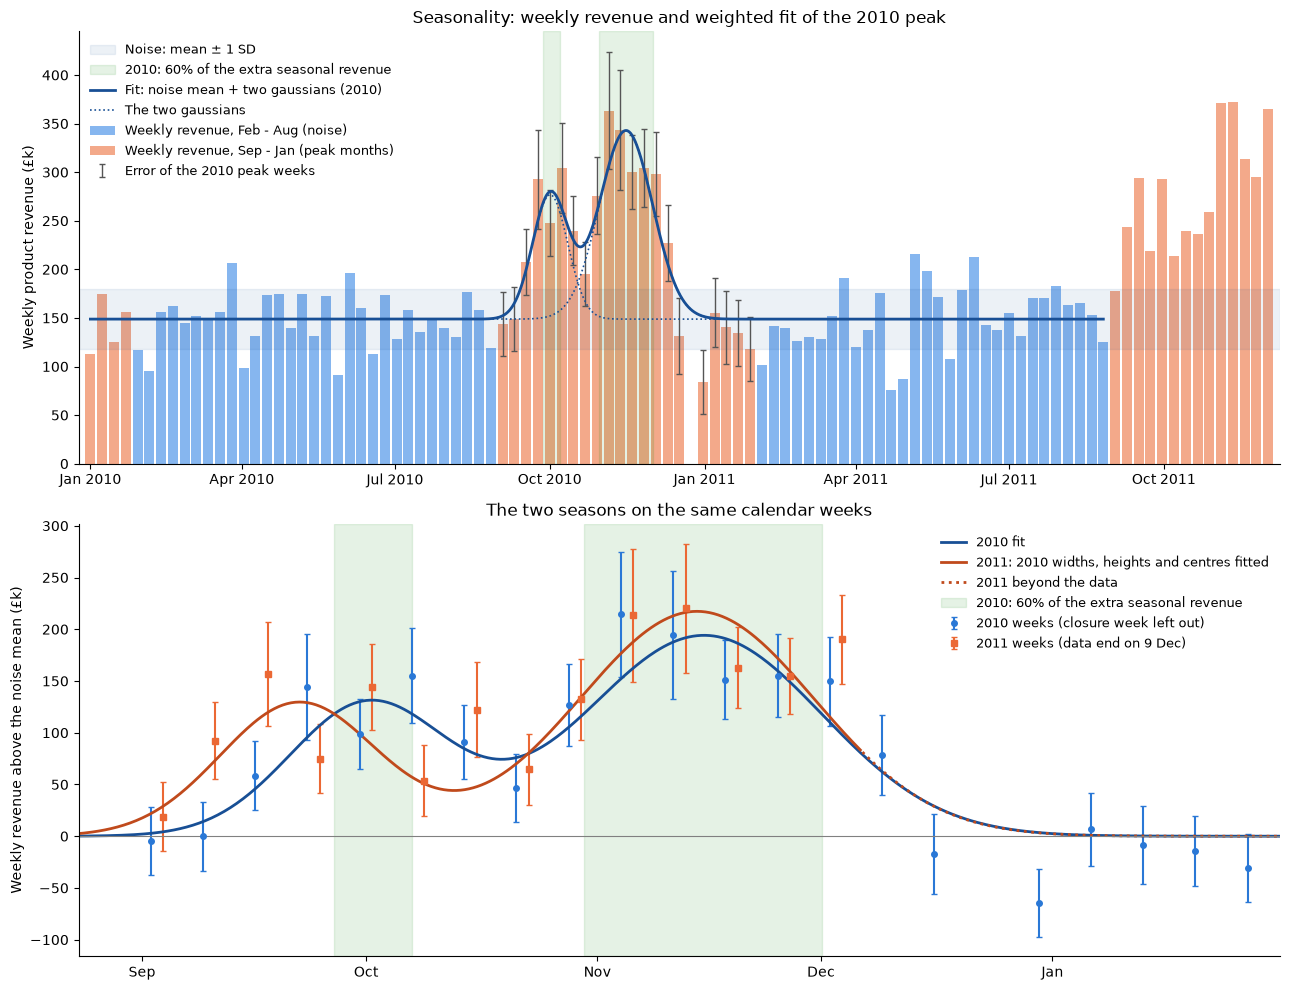

In [13]:
# Top: weekly revenue as bars (week i centred on t = i, as in the fit) and the
# fitted 2010 peak plus the noise mean, over the whole window. Bottom: the two
# seasons on the same calendar weeks, revenue above the noise with errors
t_all = np.linspace(0, len(bins10), 2000)
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(13, 10))
ax.bar(bins_all.index[~in_peak_all], bins_all.loc[~in_peak_all, "total"], width=0.85,
       color="#86b6ef", label="Weekly revenue, Feb - Aug (noise)")
ax.bar(bins_all.index[in_peak_all], bins_all.loc[in_peak_all, "total"], width=0.85,
       color="#f3a98a", label="Weekly revenue, Sep - Jan (peak months)")
ax.axhspan(noise_mean - noise_sd, noise_mean + noise_sd, color="#184f95", alpha=0.08,
           label="Noise: mean ± 1 SD")
for i, (a, b) in enumerate(regions60):
    ax.axvspan(a, b, color="#008300", alpha=0.10,
               label="2010: 60% of the extra seasonal revenue" if i == 0 else None)
ax.errorbar(t10, peak10_weeks["total"], yerr=e10, fmt="none", ecolor="#555", capsize=2, lw=1,
            label="Error of the 2010 peak weeks")
ax.plot(t_all, noise_mean + pu.two_gauss(t_all, *best["p"]), color="#184f95", lw=2,
        label="Fit: noise mean + two gaussians (2010)")
for h, mu, sg, lab in [(h1, mu1, s1, "The two gaussians"), (h2, mu2, s2, None)]:
    ax.plot(t_all, noise_mean + pu.gauss(t_all, h, mu, sg), ":", color="#184f95", lw=1.2, label=lab)
ax.legend(frameon=False, fontsize=9, loc="upper left")
ax.set_xticks(*quarter_ticks)
ax.set(xlim=(-1, len(bins_all)), ylabel="Weekly product revenue (£k)",
       title="Seasonality: weekly revenue and weighted fit of the 2010 peak")

# Bottom panel: 2010 and 2011 peaks on the same calendar weeks
t_season = np.linspace(33, 57, 600)
seen11 = t_season <= t11.max() + 0.5
ax2.errorbar(t10 - 0.12, y10, yerr=e10, fmt="o", ms=4, color="#2a78d6", capsize=2,
             label="2010 weeks (closure week left out)")
ax2.errorbar(t11 + 0.12, y11, yerr=e11, fmt="s", ms=4, color="#eb6834", capsize=2,
             label="2011 weeks (data end on 9 Dec)")
ax2.plot(t_season, pu.two_gauss(t_season, *best["p"]), color="#184f95", lw=2, label="2010 fit")
c11 = pu.two_gauss(t_season, fit11["p"][0], fit11["p"][1], s1, fit11["p"][2], fit11["p"][3], s2)
ax2.plot(t_season[seen11], c11[seen11], color="#c04a1c", lw=2,
         label="2011: 2010 widths, heights and centres fitted")
ax2.plot(t_season[~seen11], c11[~seen11], ":", color="#c04a1c", lw=2, label="2011 beyond the data")
for i, (a, b) in enumerate(regions60):
    ax2.axvspan(a, b, color="#008300", alpha=0.10,
                label="2010: 60% of the extra seasonal revenue" if i == 0 else None)
ax2.axhline(0, color="grey", lw=0.8)
season_months = pd.date_range("2010-09-01", "2011-02-01", freq="MS")
ax2.set_xticks((season_months - start10).days/7, season_months.strftime("%b"))
ax2.set(xlim=(33.5, 56.5), ylabel="Weekly revenue above the noise mean (£k)",
        title="The two seasons on the same calendar weeks")
ax2.legend(frameon=False, fontsize=9, loc="upper right")
for a in (ax, ax2):
    a.spines[["top", "right"]].set_visible(False)
pu.save_show_graph(fig, fig_dir, "seasonality_fit.png")

### Revenue concentration

- Top 20% of known customers (1,168 of 5,839): 76.7% of their product
  revenue; 23.6% of customers reach 80%.
- Top 20% of stock codes (945 of 4,722): 77.8% of product revenue.
- With non-product codes and/or customers without ID (one key per invoice):
  76.7–77.7%.

In [14]:
# Base case is "products, known customers", others are for checking sensitivity
pareto_lines = {
    "known customers (products)":  sales_with_cust,
    "known customers (all codes)": retail_df[is_known],
    "+ MISSING (products)":        sales,
    "+ MISSING (all codes)":       retail_df,
}

# Customers
cust_pareto_tables = {label: pu.pareto_table(lines.groupby("customer_key")["revenue"].sum())
                      for label, lines in pareto_lines.items()}

# Products
pr_pareto_table = (
    pu.pareto_table(sales.groupby("stock_code")["revenue"].sum())
)

# Overview pareto table with all the cases
pareto_overview = pd.DataFrame(
    [pu.pareto_summary(table, label, 20, 80)
         for label, table in cust_pareto_tables.items()]
    + [pu.pareto_summary(pr_pareto_table, "products", 20, 80)]
).set_index("group")
display(pareto_overview)

# The top 20% customers and products, from the sorted Pareto tables
n_top = pareto_overview["top_20pct_items"]
top_customers = set(cust_pareto_tables["known customers (products)"].index[:n_top["known customers (products)"]])
top_products = set(pr_pareto_table.index[:n_top["products"]])

,items,top_20pct_items,top_20pct_cum_rev,count_for_80pct_rev,pct_items_for_80pct_rev
group,,,,,
known customers (products),5839,1168,76.7,1377,23.6
known customers (all codes),5859,1172,76.8,1380,23.6
+ MISSING (products),8761,1753,77.7,1963,22.4
+ MISSING (all codes),8966,1794,77.3,2042,22.8
products,4722,945,77.8,1040,22.0


- The curves cross: at the very top single customers weigh more than single
  products; beyond about the top 15% the product curve is higher.

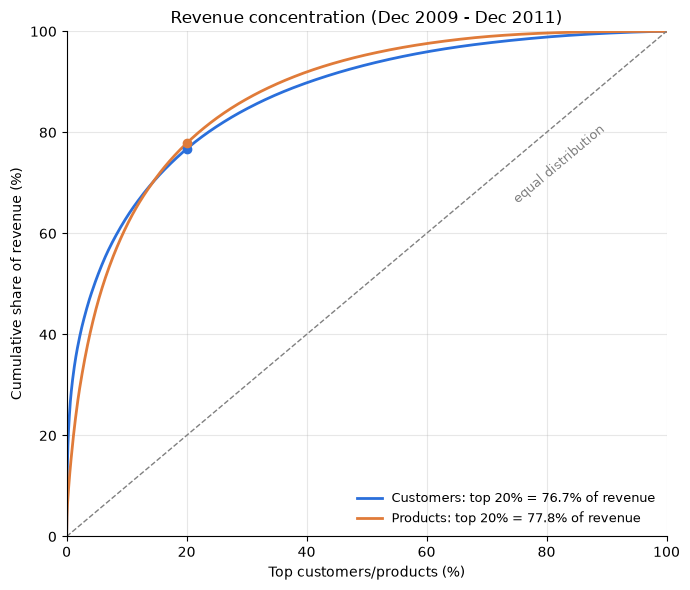

In [15]:
fig, ax = plt.subplots(figsize=(7, 6))

pareto_curves = [
    (cust_pareto_tables["known customers (products)"], "known customers (products)",
     "Customers", "#2a6fdb"),
    (pr_pareto_table, "products", "Products", "#e07b39"),
]
for table, group, label, color in pareto_curves:
    x = np.r_[0, table["cum_items"].to_numpy()]*100
    y = np.r_[0, table["cum_rev_relative"].to_numpy()]*100
    rev_top = pareto_overview.loc[group, "top_20pct_cum_rev"]
    ax.plot(x, y, color=color, linewidth=2,
            label=f"{label}: top 20% = {rev_top:.1f}% of revenue")
    ax.scatter([20], [rev_top], color=color, zorder=3)

ax.plot([0, 100], [0, 100], color="grey", linestyle="--", linewidth=1)
ax.text(74, 66, "equal distribution", color="grey", rotation=40, fontsize=9)
ax.legend(loc="lower right", frameon=False, fontsize=9)
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.set_xlabel("Top customers/products (%)")
ax.set_ylabel("Cumulative share of revenue (%)")
ax.set_title("Revenue concentration (Dec 2009 - Dec 2011)")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(alpha=0.3)
pu.save_show_graph(fig, fig_dir, "pareto_curves.png")

### Persistence of the top customers

Years from December to November.
- Of the 846 top 20% customers of 2010, 90% bought again in 2011 and 60.5%
  (512) were still in the top 20%; 252 bought below it, 82 not at all.
- 2010's top customers generated 60.8% of 2011 product revenue.

In [16]:
rev_year_cust = known_two_years.groupby(["year", "customer_id"])["revenue"].sum()
rev_2010, rev_2011 = rev_year_cust.loc[2010], rev_year_cust.loc[2011]

top_2010, top_2011 = pu.top_items(rev_2010, 20), pu.top_items(rev_2011, 20)
stayed_cust = top_2010 & top_2011
lost_cust = top_2010 - set(rev_2011.index)
downgrade_cust = top_2010 - top_2011 - lost_cust

print(f"Top 20%: in 2010 {len(top_2010)}, in 2011 {len(top_2011)}")
persistence = pd.DataFrame({"customers": [len(stayed_cust), len(downgrade_cust), len(lost_cust)]},
                           index=["top 20% in both years", "below the top 20% in 2011",
                                  "no purchases in 2011"]).rename_axis("2010 top customers")
persistence["pct_of_2010_top"] = 100*persistence["customers"]/len(top_2010)
display(persistence.round(1))
print(f"Share of 2011 revenue from 2010's top customers: "
      f"{100*rev_2011.reindex(list(top_2010)).sum()/rev_2011.sum():.1f}%")

Top 20%: in 2010 846, in 2011 857


,customers,pct_of_2010_top
2010 top customers,,
top 20% in both years,512,60.5
below the top 20% in 2011,252,29.8
no purchases in 2011,82,9.7


Share of 2011 revenue from 2010's top customers: 60.8%


### Customer features

Recency (days to 10 Dec 2011), frequency (invoices), average order value
(AOV), on product lines only; log-transformed, standardised, L1 distances.

- Monetary is dropped: 0.85 correlated with frequency on the log scale.
  Frequency–AOV 0.21, recency–frequency −0.56, recency–AOV −0.16.
- Products only against all codes: 76.7% against 76.8% for the top 20%.

In [17]:
# RFM table
# Recency is counted from the day after the last date in the data
rhythm = pu.buying_rhythm(sales_with_cust, ref_day)
rfm_df = rhythm[["recency", "frequency"]].assign(
    monetary=cust_pareto_tables["known customers (products)"]["revenue"])

# log, standardisation, L1 distances
display(np.log(rfm_df).corr().round(2))

# Monetary replaced by average order value (see below)
rfm_df["aov"] = rfm_df["monetary"]/rfm_df["frequency"]
rfm_features = ["recency", "frequency", "aov"]
rfm_log = np.log(rfm_df[rfm_features])
rfm_std = (rfm_log - rfm_log.mean())/rfm_log.std(ddof=0)
display(rfm_std.corr().round(2))

# Manhattan distances matrix (L1 norm) between all customers, for clustering
dist_l1 = cdist(rfm_std, rfm_std, metric="cityblock")

# Exact ties on the L1 distance need identical (recency, frequency, AOV) profiles
n_dup = rfm_std.duplicated().sum()
print(f"Duplicate profiles: {n_dup} of {len(rfm_std):,} customers "
      f"({100*n_dup / len(rfm_std):.1f}%)")

,recency,frequency,monetary
recency,1.00,-0.56,-0.50
frequency,-0.56,1.00,0.85
monetary,-0.50,0.85,1.00


,recency,frequency,aov
recency,1.00,-0.56,-0.16
frequency,-0.56,1.00,0.21
aov,-0.16,0.21,1.00


Duplicate profiles: 0 of 5,839 customers (0.0%)


### Clustering method and choice of k

Own k-medoids (`kmedoids.py`, ported from a C project of mine), L1,
k-means++ seeding, best of 10 runs; every segment is a real customer.

- Elbow: no clear bend. Silhouette: highest for k = 2 (0.36, active against
  inactive only); k = 4 a local maximum (0.26).
- k = 4 is chosen for the actions (see the stability check).

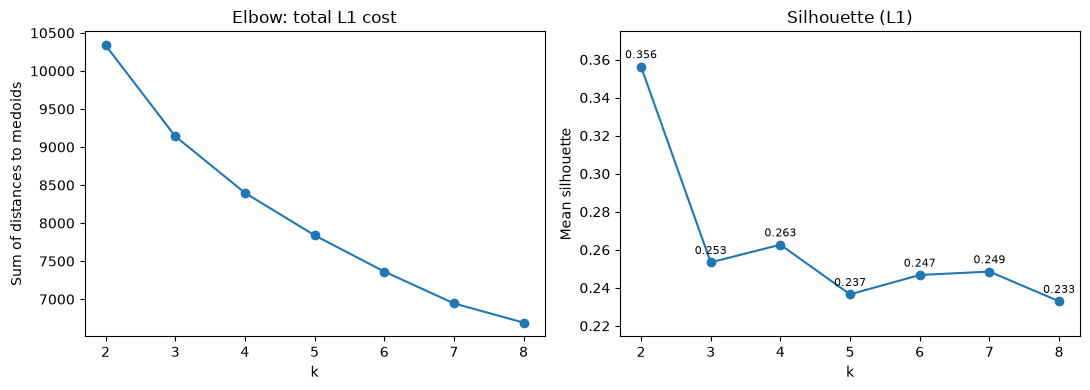

In [18]:
# k-medoids for k = 2 to 8 on all customers (10 restarts each, seed 42)
k_runs = {k: kmedoids(dist_l1, k, n_init=10, seed=42) for k in range(2, 9)}
k_scores = pd.DataFrame({"cost": {k: r["tot_cost"] for k, r in k_runs.items()},
                         "silhouette": {k: silhouette(dist_l1, r["labels"]) for k, r in k_runs.items()}})

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(k_scores.index, k_scores["cost"], marker="o")
axes[0].set(title="Elbow: total L1 cost", xlabel="k",
            ylabel="Sum of distances to medoids")
axes[1].plot(k_scores.index, k_scores["silhouette"], marker="o")
for k, v in k_scores["silhouette"].items():
    axes[1].annotate(f"{v:.3f}", (k, v), xytext=(0, 6), textcoords="offset points",
                     ha="center", fontsize=8)
axes[1].set(title="Silhouette (L1)", xlabel="k", ylabel="Mean silhouette")
axes[1].margins(y=0.15)
pu.save_show_graph(fig, fig_dir, "kmedoids_choice_of_k.png")

### Customer segments

- Core loyal: frequent, recent, large orders; a fifth of the customers,
  almost three quarters of the revenue.
- Lapsing regulars: several orders almost as large, last purchase about
  7 months ago.
- Recent occasional: recent, few small orders.
- Lost one-timers: one small order, more than a year ago.
- Mean silhouette 0.26: a partition for action, not natural types.
- Top 20% customers: 947 of 1,168 are core loyal (81%, 89% of their
  revenue); 73% of core loyal customers are in the top 20%; lapsing
  regulars 197 (17%).

In [19]:
km_final = k_runs[4]          # computed in the choice of k
labels = km_final["labels"]
rfm_df["cluster"] = labels
mean_dist = mean_dist_to_clusters(dist_l1, labels)
rfm_df["silhouette"] = silhouette_samples(mean_dist, labels)
print("Mean silhouette:", round(rfm_df["silhouette"].mean(), 3))

# Cluster profile: medians are robust to the long tails
profile = rfm_df.groupby("cluster").agg(
    customers=("cluster", "size"),
    recency_median=("recency", "median"),
    frequency_median=("frequency", "median"),
    aov_median=("aov", "median"),
    revenue=("monetary", "sum"),
)
profile["customers_pct"] = 100*profile["customers"]/profile["customers"].sum()
profile["revenue_pct"] = 100*profile["revenue"]/profile["revenue"].sum()

# Segment names (cluster numbers are fixed by seed=42)
segment_names = {1: "Core loyal", 3: "Lapsing regulars",
                 2: "Recent occasional", 0: "Lost one-timers"}
rfm_df["segment"] = rfm_df["cluster"].map(segment_names)
display(profile.rename(index=segment_names).rename_axis("segment")
        .sort_values("revenue", ascending=False)
        .round({"recency_median": 1, "frequency_median": 1, "aov_median": 2, "revenue": 2,
                "customers_pct": 1, "revenue_pct": 1}))
# Medoids: a real "typical customer" for each segment
medoids = rfm_df.iloc[km_final["medoids"]]
display(medoids[["cluster", "segment", "recency", "frequency", "aov", "monetary"]].round(2))

# Where are the top 20% customers of the Pareto analysis?
display(pu.top_by_group(rfm_df["segment"], rfm_df["monetary"], top_customers)
        .reindex(segment_names.values()).round(1))

Mean silhouette: 0.263


,customers,recency_median,frequency_median,aov_median,revenue,customers_pct,revenue_pct
segment,,,,,,,
Core loyal,1301,17.0,12.0,360.63,12007162.51,22.3,73.2
Lapsing regulars,1476,219.0,4.0,320.93,2750621.05,25.3,16.8
Recent occasional,1254,26.0,3.0,218.68,1031292.29,21.5,6.3
Lost one-timers,1808,407.0,1.0,200.53,618070.44,31.0,3.8


,cluster,segment,recency,frequency,aov,monetary
customer_key,,,,,,
14278,0,Lost one-timers,410,1,205.83,205.83
14334,1,Core loyal,17,12,357.75,4292.98
17777,2,Recent occasional,25,3,215.85,647.56
17142,3,Lapsing regulars,240,4,318.81,1275.25


,items,top_items,pct_of_top,pct_of_top_revenue,pct_of_group_in_top
segment,,,,,
Core loyal,1301,947,81.1,89.4,72.8
Lapsing regulars,1476,197,16.9,9.5,13.3
Recent occasional,1254,15,1.3,0.6,1.2
Lost one-timers,1808,9,0.8,0.5,0.5


Stability over other seeds:
- Cost within 0.2% (8,389–8,408 against 8,398).
- Core loyal robust: 81–95% stay together. The other segments: 53–80%;
  some solutions split inactive customers by order value instead of number
  of orders. The split by orders is kept: Win back needs former regulars.
- Silhouettes 0.23–0.26 for k = 3 to 6 (k = 4: 0.237–0.244): the silhouette
  cannot choose. k = 3 mixes lapsing regulars and recent occasionals
  (median recency 79 days); k = 5 splits by order value (one-timers at £129
  and £360), with no new action.

In [20]:
# 1. Other seeds (10 restarts each), k = 3 to 6: the mean silhouette and, for
#    k = 4, the total cost and, for each segment, the largest share of its
#    customers that stays together in one cluster
sil_by_seed = {42: k_scores.loc[3:6, "silhouette"]}
stability = [{"seed": 42, "cost": km_final["tot_cost"],
              **dict.fromkeys(segment_names.values(), 100.0)}]
for seed in [1, 2, 3]:
    runs = {k: kmedoids(dist_l1, k, n_init=10, seed=seed) for k in range(3, 7)}
    sil_by_seed[seed] = pd.Series({k: silhouette(dist_l1, r["labels"]) for k, r in runs.items()})
    seg_crosstab = pd.crosstab(rfm_df["segment"], runs[4]["labels"])
    stability.append({"seed": seed, "cost": runs[4]["tot_cost"],
                      **(100*seg_crosstab.max(axis=1)/seg_crosstab.sum(axis=1)).to_dict()})
stability = pd.DataFrame(stability).set_index("seed")
display(stability.round(1).assign(cost=stability["cost"].round(2)))
display(pd.DataFrame(sil_by_seed).rename_axis(index="k", columns="seed: mean silhouette").round(3))

# 2. What k = 3 and k = 5 would give: the chosen segments in each cluster,
#    and the cluster medians
for k in [3, 5]:
    lab_k = pd.Series(k_runs[k]["labels"], index=rfm_df.index, name=f"k={k} cluster")
    print(f"\nk = {k}:")
    display(pd.crosstab(rfm_df["segment"], lab_k))
    display(rfm_df.groupby(lab_k)[["recency", "frequency", "aov"]].median()
            .round({"recency": 1, "frequency": 1, "aov": 2}).T.rename_axis("median"))

,cost,Core loyal,Lapsing regulars,Recent occasional,Lost one-timers
seed,,,,,
42,8397.68,100.0,100.0,100.0,100.0
1,8407.88,91.8,59.4,79.7,71.5
2,8392.08,81.5,53.3,73.9,61.4
3,8388.61,95.1,63.3,69.5,57.7


seed: mean silhouette,42,1,2,3
k,,,,
3,0.253,0.245,0.247,0.253
4,0.263,0.244,0.237,0.238
5,0.237,0.250,0.259,0.233
6,0.247,0.255,0.259,0.257



k = 3:


k=3 cluster,0,1,2
segment,,,
Core loyal,1231,0,70
Lapsing regulars,87,235,1154
Lost one-timers,0,1680,128
Recent occasional,264,93,897


k=3 cluster,0,1,2
median,,,
recency,17.50,402.00,79.00
frequency,11.00,1.00,3.00
aov,313.58,180.63,329.34



k = 5:


k=5 cluster,0,1,2,3,4
segment,,,,,
Core loyal,0,1020,32,249,0
Lapsing regulars,301,18,491,586,80
Lost one-timers,779,0,93,0,936
Recent occasional,78,206,794,128,48


k=5 cluster,0,1,2,3,4
median,,,,,
recency,396.00,12.00,65.00,85.00,403.50
frequency,1.00,11.00,3.00,5.00,1.00
aov,359.84,313.04,199.51,491.66,129.28


Graph. Left: recency and frequency, medoids as stars. Right: AOV by segment.

- Segments split mainly by recency and frequency and overlap at the borders
  (the AOV is not in the left panel); Upgrade and Retain look there.
- Order values overlap widely: lowest median for lost one-timers, highest
  for core loyal.

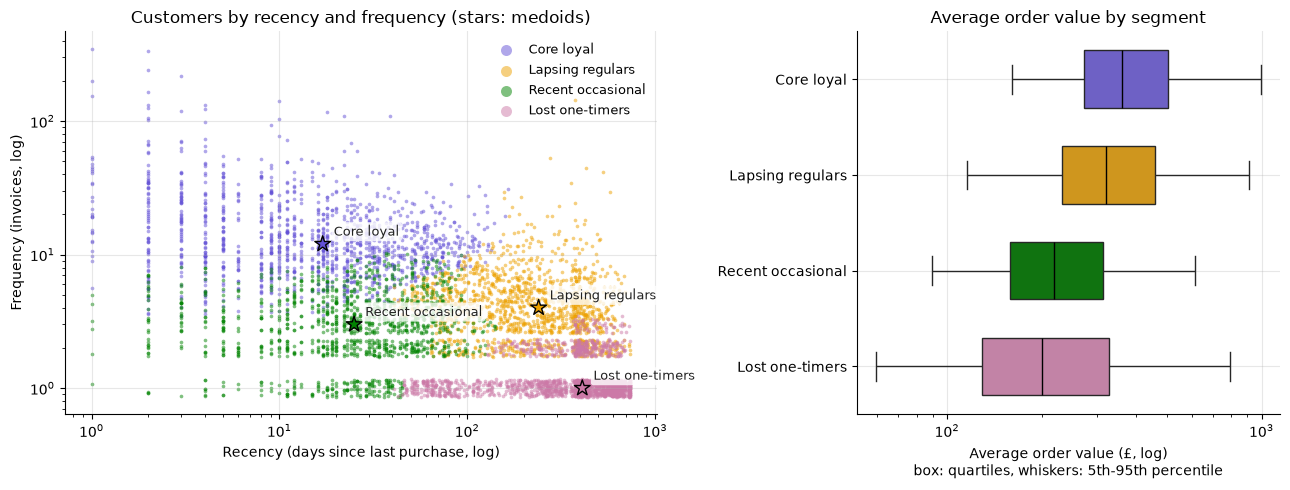

In [21]:
# Left: recency and frequency of every customer (log scales; frequency is an
# integer, so points get a small random jitter to show their density), with
# the medoid of each segment. Right: average order value per segment.
# Four hues far apart also for colour-blind readers (checked on all pairs)
seg_colors = dict(zip(segment_names.values(), ["#6250d6", "#eda100", "#008300", "#cc79a7"]))
jitter = np.exp(np.random.default_rng(0).uniform(-0.15, 0.15, len(rfm_df)))
fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.4, 1]})
for name, color in seg_colors.items():
    seg = rfm_df["segment"] == name
    axes[0].scatter(rfm_df.loc[seg, "recency"], rfm_df.loc[seg, "frequency"]*jitter[seg],
                    s=7, alpha=0.5, color=color, linewidths=0, label=name)
axes[0].scatter(medoids["recency"], medoids["frequency"], s=140, marker="*",
                color=medoids["segment"].map(seg_colors), edgecolors="black", linewidths=1,
                zorder=3)
for _, m in medoids.iterrows():
    axes[0].annotate(m["segment"], (m["recency"], m["frequency"]), xytext=(8, 6),
                     textcoords="offset points", fontsize=9, color="#222",
                     bbox={"boxstyle": "round,pad=0.2", "fc": "white", "ec": "none", "alpha": 0.8})
axes[0].set(xscale="log", yscale="log", xlabel="Recency (days since last purchase, log)",
            ylabel="Frequency (invoices, log)",
            title="Customers by recency and frequency (stars: medoids)")
axes[0].legend(frameon=False, fontsize=9, markerscale=3, loc="upper right")

# Whiskers at the 5th and 95th percentiles: percentiles do not change on a log axis
sns.boxplot(data=rfm_df, x="aov", y="segment", hue="segment", order=list(seg_colors),
            palette=seg_colors, legend=False, whis=(5, 95), showfliers=False, width=0.6,
            medianprops={"color": "black"}, ax=axes[1])
axes[1].set(xscale="log", ylabel="",
            xlabel="Average order value (£, log)\nbox: quartiles, whiskers: 5th-95th percentile",
            title="Average order value by segment")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(alpha=0.3, which="major")
pu.save_show_graph(fig, fig_dir, "customer_segments.png")

### Customer actions

Signals, thresholds fixed before the backtest:
- Overdue (core loyal): recency / own mean gap, (last − first) / (orders −
  1); single-order customers use the core-loyal median gap, 49 days.
  Overdue = 2 missed orders (probability e^−2 ≈ 13.5% under a constant
  rate).
- P(alive) (lapsing regulars): BG/NBD (Fader, Hardie and Lee, 2005), 4
  parameters fitted on all known customers; < 0.4 = probably lost. Not for
  core loyal (median 0.99, lowest 10% 0.97) nor recent occasional (0.96).
- Silhouette towards another segment < 0.1 (recent occasional): close to it.

| Action | Rule | Owner |
|---|---|---|
| Protect | Core loyal, overdue, top 20% customers (£2,850 or more) | account managers |
| Win back | Lapsing regular, P(alive) < 0.4, top 20% customers | account managers |
| Upgrade | Recent occasional, close to core loyal | sales |
| Retain | Recent occasional, close to lost one-timers | automated campaigns |

- The top 20% filter: Win back 43 instead of 152, Protect 54 instead of 61.
- Priority: Protect and Win back by revenue, Upgrade by order size, Retain
  by recency.
- Protect is led by a £97k customer with 103 orders, silent 39 days (5.7
  gaps). Win back: silent 276–373 days, P(alive) near 0, including a buyer
  of 27 orders of about £2k. Upgrade: orders up to about £4k.
- Sensitivity: overdue 1.5 / 3 gives Protect 97 / 24; P(alive) 0.3 / 0.5
  gives Win back 39 / 49; silhouette 0.05 / 0.2 gives Upgrade 40 / 233 and
  Retain 28 / 167 (the threshold that matters most). Upgrade and Retain are
  not backtested.

In [22]:
sil_max = 0.1        # "close to another segment": silhouette towards it below 0.1
overdue_min = 2      # silent for at least two typical gaps between orders
p_alive_max = 0.4    # "probably lost": BG/NBD probability of being active below 40%

cluster_of = {name: c for c, name in segment_names.items()}
sil_vs_core = silhouette_vs(mean_dist, labels, cluster_of["Core loyal"])
sil_vs_lost = silhouette_vs(mean_dist, labels, cluster_of["Lost one-timers"])
is_core, is_lapsing, is_recent = (rfm_df["segment"] == s for s in
                                  ["Core loyal", "Lapsing regulars", "Recent occasional"])

# Personal inactivity: recency measured in typical gaps of the customer.
# Customers without a gap (one invoice, or all on the same day) get the
# median gap of the core loyal, the rhythm we aim for.
core_gap = rhythm.loc[is_core, "mean_gap"].median()
rfm_df["overdue"] = rfm_df["recency"]/rhythm["mean_gap"].fillna(core_gap)
# Value worth a personal contact: the lowest revenue of the top 20% customers
# of the Pareto analysis
top_value = rfm_df.loc[list(top_customers), "monetary"].min()
display(pd.Series({"median gap of core loyals (days)": round(core_gap),
                   "revenue threshold of the top 20% customers (£)": round(top_value, 2)},
                  name="value", dtype=object).to_frame())

# Probability of being still active: BG/NBD fitted on all known customers
bg_data = pu.bgnbd_inputs(sales_with_cust, ref_day)
bg_par = pu.bgnbd_fit(bg_data)
rfm_df["p_alive"] = pu.bgnbd_p_alive(bg_data, bg_par)
display(bg_par.round(3).rename("BG/NBD parameter (weeks)").to_frame())
display(rfm_df.groupby("segment")["p_alive"].describe(percentiles=[0.1, 0.5])
        [["count", "10%", "50%"]].reindex(segment_names.values()).round(2))

is_overdue = rfm_df["overdue"] >= overdue_min
is_lost = rfm_df["p_alive"] < p_alive_max
rfm_df["action"] = pu.customer_actions(rfm_df, is_overdue, is_lost, sil_vs_core, sil_vs_lost, sil_max, top_value)
short_cust_action = pu.short_action(rfm_df["action"])
# Protect and Win back with and without the value filter
display(pd.DataFrame({
    "customers": [(short_cust_action == a).sum() for a in ["Protect", "Win back"]],
    "without the value filter": [(is_core & is_overdue).sum(), (is_lapsing & is_lost).sum()],
}, index=["Protect", "Win back"]))
print(f"In both Upgrade and Retain: {((sil_vs_core < sil_max) & (sil_vs_lost < sil_max) & is_recent).sum()}")

# Examples: the first 3 customers of each action, by its priority
priority = {"Protect": (["monetary"], [False]),
            "Win back": (["monetary"], [False]),
            "Upgrade": (["aov", "frequency"], [False, False]),
            "Retain": (["recency", "aov"], [False, False])}
display(pd.concat([rfm_df[short_cust_action == name].sort_values(by, ascending=asc).head(3)
                   for name, (by, asc) in priority.items()])
        .assign(action=short_cust_action)
        [["action", "segment", "recency", "frequency", "aov", "monetary", "overdue", "p_alive"]]
        .round(2))

# Sensitivity: customers per action with other rules
cust_variants = {
    "chosen rules": (is_overdue, is_lost, sil_max),
    "overdue >= 1.5": (rfm_df["overdue"] >= 1.5, is_lost, sil_max),
    "overdue >= 3": (rfm_df["overdue"] >= 3, is_lost, sil_max),
    "P(alive) < 0.3": (is_overdue, rfm_df["p_alive"] < 0.3, sil_max),
    "P(alive) < 0.5": (is_overdue, rfm_df["p_alive"] < 0.5, sil_max),
    "silhouette < 0.05": (is_overdue, is_lost, 0.05),
    "silhouette < 0.2": (is_overdue, is_lost, 0.2),
}
display(pu.action_counts({name: pu.customer_actions(rfm_df, od, lost, sil_vs_core, sil_vs_lost, sil, top_value)
                          for name, (od, lost, sil) in cust_variants.items()}))

,value
median gap of core loyals (days),49
revenue threshold of the top 20% customers (£),2850.29


,BG/NBD parameter (weeks)
r,0.670
alpha,9.185
a,0.110
b,2.367


,count,10%,50%
segment,,,
Core loyal,1301.0,0.97,0.99
Lapsing regulars,1476.0,0.40,0.88
Recent occasional,1254.0,0.94,0.96
Lost one-timers,1808.0,0.76,1.00


,customers,without the value filter
Protect,54,61
Win back,43,152


In both Upgrade and Retain: 0


,action,segment,recency,frequency,aov,monetary,overdue,p_alive
customer_key,,,,,,,,
16029,Protect,Core loyal,39,103,942.40,97066.71,5.74,0.95
16422,Protect,Core loyal,18,105,575.02,60377.07,2.76,0.99
14680,Protect,Core loyal,26,57,936.14,53360.13,2.05,0.99
16754,Win back,Lapsing regulars,373,27,2033.46,54903.39,36.05,0.00
13093,Win back,Lapsing regulars,276,55,972.42,53483.05,32.40,0.00
17850,Win back,Lapsing regulars,373,155,327.52,50766.02,158.68,0.00
16000,Upgrade,Recent occasional,3,3,4131.23,12393.70,0.06,1.00
15195,Upgrade,Recent occasional,3,1,3861.00,3861.00,0.06,1.00
15113,Upgrade,Recent occasional,10,3,1113.04,3339.12,0.44,0.96


,No action,Protect,Retain,Upgrade,Win back
chosen rules,5575,54,81,86,43
overdue >= 1.5,5532,97,81,86,43
overdue >= 3,5605,24,81,86,43
P(alive) < 0.3,5579,54,81,86,39
P(alive) < 0.5,5569,54,81,86,49
silhouette < 0.05,5674,54,28,40,43
silhouette < 0.2,5342,54,167,233,43


Protect: unusual silences or seasonal pauses? Each silence moved back one
year:
- 43 of 54 (£553k of £644k) bought in that window a year earlier: unusual
  silence; 2 silent then too; 9 not yet customers.
- Weak check for short silences: shortest 18 days (median 95.0), right
  after the season. The list is kept as it is.

In [23]:
# For each Protect customer, the window of their silence (from the day after
# the last purchase to the end of the data) moved back one year (365 days):
# invoices in it. Some: a year earlier they were buying at that time, so the
# silence is unusual. None: they were silent then too, the pause may be
# seasonal. Customers whose first purchase falls after the start of that
# window had no history yet.
protect = rfm_df.index[short_cust_action == "Protect"]
silence_start = rhythm.loc[protect, "last"].dt.normalize() + pd.Timedelta(days=1)
one_year = pd.Timedelta(days=365)
year_before = pu.invoices_between(sales_with_cust, silence_start - one_year, ref_day - one_year, protect)
protect_status = pd.Series(np.select(
    [rhythm.loc[protect, "first"] > silence_start - one_year, year_before > 0],
    ["no history a year earlier", "bought a year earlier: unusual silence"],
    "silent a year earlier too: seasonal pause?"), index=protect, name="Protect customers")
protect_frame = rfm_df.loc[protect, ["monetary", "recency"]].assign(group=protect_status)
protect_agg = dict(customers=("monetary", "size"), revenue=("monetary", "sum"),
                   shortest_silence_days=("recency", "min"),
                   median_silence_days=("recency", "median"))
display(pd.concat([protect_frame.groupby("group").agg(**protect_agg),
                   protect_frame.assign(group="All").groupby("group").agg(**protect_agg)])
        .rename_axis("Protect customers")
        .round({"revenue": 2, "median_silence_days": 1}))

,customers,revenue,shortest_silence_days,median_silence_days
Protect customers,,,,
bought a year earlier: unusual silence,43,552891.54,18,106.0
no history a year earlier,9,55179.62,18,74.0
silent a year earlier too: seasonal pause?,2,35735.15,43,72.0
All,54,643806.31,18,95.0


Win back and the season: BG/NBD assumes a constant buying rate. Shortest
Win back silence 157 days (median 408.0): all missed the autumn peak.

In [24]:
# Days since the last purchase (recency) per action, at the end of the data
display(rfm_df[short_cust_action != "No action"].groupby(short_cust_action)["recency"]
        .agg(customers="size", shortest_silence_days="min", median_silence_days="median")
        .round({"median_silence_days": 1}))

,customers,shortest_silence_days,median_silence_days
action,,,
Protect,54,18,95.0
Retain,81,19,41.0
Upgrade,86,1,23.0
Win back,43,157,408.0


### Customers behind each action

- 264 customers (4.5%) are candidates for action, £1.27M (7.7%) of past
  product revenue; 5,575 get no action.
- `output/customer_segments.csv`: all 5,839 known customers with segment,
  action and reason, recency, frequency, AOV, revenue and P(alive), sorted by
  segment and revenue.

In [25]:
# Customers and revenue (Dec 2009 - Dec 2011) behind each action
action_summary = rfm_df.groupby("action").agg(
    customers=("monetary", "size"),
    revenue=("monetary", "sum"),
    revenue_median=("monetary", "median"),
)
display(action_summary.sort_values("revenue", ascending=False).round(2))
has_action = rfm_df["action"] != "No action"
rev_action = rfm_df.loc[has_action, "monetary"].sum()
print(f"Customers with an action: {has_action.sum()} ({100*has_action.mean():.1f}%), "
      f"£{rev_action/1e6:.2f}M of past product revenue "
      f"({100*rev_action/rfm_df['monetary'].sum():.1f}%)")

# For Power BI: overdue, the top 20% customers of the Pareto analysis and the
# medoids (the typical customer of each segment)
rfm_df["top_20pct"] = rfm_df.index.isin(list(top_customers))
rfm_df["is_medoid"] = rfm_df.index.isin(medoids.index)
export_cols = ["segment", "action", "recency", "frequency", "aov", "monetary", "overdue", "p_alive",
               "top_20pct", "is_medoid"]
(rfm_df[export_cols].round({"overdue": 2, "p_alive": 3})
 .sort_values(["segment", "monetary"], ascending=[True, False])
 .to_csv(out_dir/"customer_segments.csv"))

,customers,revenue,revenue_median
action,,,
No action,5575,15136618.18,821.35
"Protect: core customer, overdue",54,643806.31,7012.27
"Win back: lapsing, probably lost",43,444824.83,4818.35
"Upgrade: recent, close to core",86,154451.58,1581.10
"Retain: recent, slipping towards lost",81,27445.39,266.12


Customers with an action: 264 (4.5%), £1.27M of past product revenue (7.7%)


### Backtest of the overdue and P(alive) rules

Dates 1 Dec 2010, 1 Mar 2011, 1 Jun 2011; only the purchases before each
date (BG/NBD refitted). Small leak: returns are matched on the whole data.
1 Sep 2010 (9 months of history) left out: no customer flagged.

- Overdue, regular customers (10+ invoices), invoices in the next 6 months
  against the same months a year earlier (median): 31–43% if overdue,
  78–89% for the others. Same months: no season in the comparison.
- P(alive) < 0.4, customers with 3+ invoices, back within 6 months: 20.0%
  (March 2011, 25 flagged) and 21.1% (June 2011, 76) against 67.8% and
  73.2%. December 2010: 3 flagged, 1 back. At the end of the data: 152
  lapsing regulars.
- Tested: the two rules, not the actions (segments not rebuilt at each
  date); the dates overlap, so they are not independent tests.

In [26]:
# Each rule is applied at three past dates, using only the purchases before
# them (net of returns, matched on the whole data; BG/NBD is fitted again at each date), and checked on what it is for.
# - Overdue flags regular customers who are slowing down: in the next 6
#   months, do they buy less than in the same 6 months a year earlier?
#   Customers with 10+ invoices and at least one in that earlier period.
# - P(alive) flags customers who are probably lost: do they come back in the
#   next 6 months? Customers with 3+ invoices.
cutoffs = pd.to_datetime(["2010-12-01", "2011-03-01", "2011-06-01"])   # a year of history at least
min_inv_overdue, min_inv_lost = 10, 3   # regular customers (core loyal: median 12); lapsing regulars: 4
bt_overdue, bt_lost = {}, {}
for cutoff in cutoffs:
    bt = pu.backtest_customers(sales_with_cust, cutoff)
    regular = bt[(bt["frequency"] >= min_inv_overdue) & (bt["invoices_year_before"] > 0)]
    od = regular["overdue"] >= overdue_min
    ratio = regular["invoices_next"]/regular["invoices_year_before"]
    bt_overdue[f"{cutoff:%b %Y}"] = {"customers": len(regular), "overdue": od.sum(),
                                     "median ratio, overdue": ratio[od].median(),
                                     "median ratio, others": ratio[~od].median()}
    repeat = bt[bt["frequency"] >= min_inv_lost]
    lost = repeat["p_alive"] < p_alive_max
    bt_lost[f"{cutoff:%b %Y}"] = {
        "customers": len(repeat), "probably lost": lost.sum(),
        "back in 6 months (%), probably lost": 100*repeat.loc[lost, "returned"].mean(),
        "back in 6 months (%), others": 100*repeat.loc[~lost, "returned"].mean()}
display(pd.DataFrame(bt_overdue).T.astype({"customers": int, "overdue": int}).round(2)
        .rename_axis(f"overdue >= 2, {min_inv_overdue}+ invoices: "
                     "invoices in the next 6 months / same 6 months a year earlier"))
display(pd.DataFrame(bt_lost).T.astype({"customers": int, "probably lost": int}).round(1)
        .rename_axis(f"P(alive) < {p_alive_max}, {min_inv_lost}+ invoices"))

,customers,overdue,"median ratio, overdue","median ratio, others"
"overdue >= 2, 10+ invoices: invoices in the next 6 months / same 6 months a year earlier",,,,
Dec 2010,356,39,0.31,0.80
Mar 2011,477,124,0.43,0.89
Jun 2011,609,122,0.33,0.78


,customers,probably lost,"back in 6 months (%), probably lost","back in 6 months (%), others"
"P(alive) < 0.4, 3+ invoices",,,,
Dec 2010,1986,3,33.3,70.5
Mar 2011,2232,25,20.0,67.8
Jun 2011,2493,76,21.1,73.2


### Price bands

- A product sells at 4.6 prices on average; lines without ID pay about
  twice as much (median ratio 1.99 over 4,096 products sold both ways).
- Reference price: median unit price of known customers; lines without ID
  only for the 111 products no known customer bought.

In [27]:
# The same product is sold at several prices: how many, and how different
# for lines with and without customer ID?
prices = sales.groupby("stock_code")["price"].agg(n_prices="nunique", median_all="median")
by_id = (sales.groupby(["stock_code", "is_missing_customer"])["price"].median()
         .unstack().rename(columns={0: "known", 1: "without_id"}))
display(pd.Series({
    "distinct prices per product, mean": round(prices["n_prices"].mean(), 2),
    "distinct prices per product, median": int(prices["n_prices"].median()),
    "distinct prices per product, max": int(prices["n_prices"].max()),
    "products bought with and without customer ID": len(by_id.dropna()),
    "median price ratio, without ID / known": round((by_id["without_id"]/by_id["known"]).median(), 2),
    "products bought only without customer ID": int(by_id["known"].isna().sum()),
}, name="value", dtype=object).to_frame())

# Reference price: median over the lines of known customers; lines without
# ID only for the products no known customer bought
ref_price = by_id["known"].fillna(prices["median_all"]).rename("ref_price")

,value
"distinct prices per product, mean",4.55
"distinct prices per product, median",4
"distinct prices per product, max",21
products bought with and without customer ID,4096
"median price ratio, without ID / known",1.99
products bought only without customer ID,111


Bands by quartile of reference price: below £1.25, £1.25–2.10, £2.10–4.24,
£4.24 and up, intervals [a, b).
- Ties (588 products at £1.25, 200 at £2.10): bands hold 23–26% of the
  products each.

In [28]:
band_names = ["Low", "Mid-low", "Mid-high", "High"]
price_band, band_edges = pu.price_bands(ref_price, 4, band_names)
# Prices repeat (round list prices): products exactly on each edge
display(pd.DataFrame({"edge_gbp": band_edges.round(2),
                      "products_exactly_on_edge": [int((ref_price == e).sum()) for e in band_edges]}))

,edge_gbp,products_exactly_on_edge
0,1.25,588
1,2.10,200
2,4.24,0


- Cheapest quarter: 40% of the units, 12.5% of the revenue (8 units per
  line against 2); most expensive: 8% of the units, 31% of the revenue.
- Above the lowest band, 28–31% of the revenue per band.
- Every segment and the lines without ID spend 28–32% on high-price and
  12–15% on low-price products: segments differ in how often and how much,
  not in price.
- Pricing on all lines: 321 products (6.8%) change band, mostly sold
  without ID (median 55.6% of their lines against 20.1% for the 4,401
  others); revenue by band barely changes (largest gap Mid-high, 28.2%
  against 27.6%).
- Top 20% products (945): 12.5% in the lowest band, 28–30% in each other;
  10.8% of low-price products are in the top 20%, against 22–24%.

In [29]:
segment_order = list(segment_names.values()) + ["No customer ID"]
band_table = pu.band_summary(sales, price_band)
mix_table = pu.segment_mix(sales, price_band, rfm_df["segment"]).reindex(segment_order)
display(band_table.round({c: 1 if c.endswith("_pct") or c.startswith("median") else 2
                          for c in band_table.columns}))
display(mix_table.round(1))

# Check: bands priced on all lines (also without customer ID). Which products
# move, and does the revenue by band change?
alt_band = pu.price_bands(prices["median_all"], 4, band_names)[0]
moved = price_band.astype(str) != alt_band.astype(str)
share_no_id = sales.groupby("stock_code")["is_missing_customer"].mean()
display(pd.DataFrame({
    "products": moved.value_counts(),
    "% of products": 100*moved.value_counts(normalize=True),
    "median % of their lines without customer ID": 100*share_no_id.groupby(moved).median(),
}).rename(index={False: "same band", True: "another band"})
  .rename_axis("bands priced on all lines").round(1))
display(pd.DataFrame({"% of revenue, bands priced on known customers (chosen)":
                          band_table["revenue_pct"],
                      "% of revenue, bands priced on all lines":
                          pu.band_summary(sales, alt_band)["revenue_pct"]})
        .round(1))

# Where are the top 20% products of the Pareto analysis?
display(pu.top_by_group(price_band, pr_pareto_table["revenue"], top_products).round(1))

,products,units,revenue,avg_price_paid,median_units_per_line,products_pct,units_pct,revenue_pct
band,,,,,,,,
Low,1094,4270951,2370788.38,0.56,8.0,23.2,39.7,12.5
Mid-low,1246,3704735,5547180.02,1.50,5.0,26.4,34.4,29.2
Mid-high,1201,1905425,5236169.81,2.75,3.0,25.4,17.7,27.6
High,1181,875334,5830043.15,6.66,2.0,25.0,8.1,30.7


band,Low,Mid-low,Mid-high,High
segment,,,,
Core loyal,11.9,29.9,27.6,30.6
Lapsing regulars,13.5,28.5,26.8,31.2
Recent occasional,13.7,30.0,28.2,28.1
Lost one-timers,14.6,27.2,27.5,30.7
No customer ID,13.3,26.9,27.9,31.8


,products,% of products,median % of their lines without customer ID
bands priced on all lines,,,
same band,4401,93.2,20.1
another band,321,6.8,55.6


,"% of revenue, bands priced on known customers (chosen)","% of revenue, bands priced on all lines"
band,,
Low,12.5,12.1
Mid-low,29.2,29.0
Mid-high,27.6,28.2
High,30.7,30.7


,items,top_items,pct_of_top,pct_of_top_revenue,pct_of_group_in_top
band,,,,,
Low,1094,118,12.5,9.2,10.8
Mid-low,1246,277,29.3,29.6,22.2
Mid-high,1201,266,28.1,28.6,22.1
High,1181,284,30.1,32.6,24.0


Graph. Left: products, units and revenue by band. Right: revenue of each
segment, and of the lines without ID, by band.

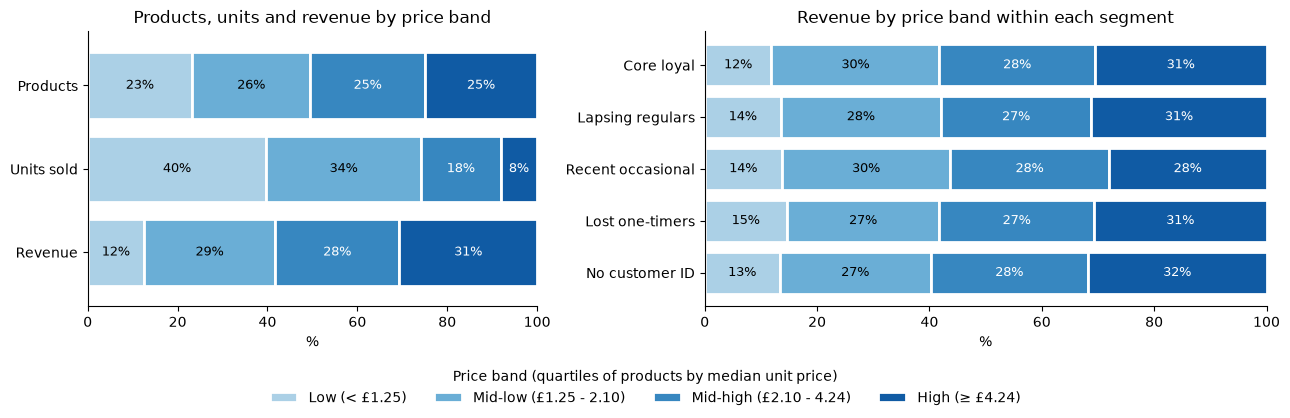

In [30]:
def stacked_share_bars(ax, table, title):
    """100% stacked horizontal bars (first row of table at the top), each
    segment labelled with its share when >= 6%."""
    table.iloc[::-1].plot.barh(stacked=True, color=band_colors, edgecolor="white", linewidth=2,
                               width=0.8, legend=False, ax=ax)
    for i, bars in enumerate(ax.containers):
        ax.bar_label(bars, labels=[f"{v:.0f}%" if v >= 6 else "" for v in bars.datavalues],
                     label_type="center", fontsize=9, color="black" if i < 2 else "white")
    ax.set(xlim=(0, 100), title=title, xlabel="%", ylabel="")
    ax.spines[["top", "right"]].set_visible(False)

band_colors = sns.color_palette("Blues", len(band_names) + 1)[1:]  # light = cheap
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2),
                         gridspec_kw={"width_ratios": [1, 1.25]})
stacked_share_bars(axes[0], band_table[["products_pct", "units_pct", "revenue_pct"]].T
                   .set_axis(["Products", "Units sold", "Revenue"]),
                   "Products, units and revenue by price band")
stacked_share_bars(axes[1], mix_table, "Revenue by price band within each segment")

legend_labels = [f"Low (< £{band_edges[0]:.2f})", f"Mid-low (£{band_edges[0]:.2f} - {band_edges[1]:.2f})",
                 f"Mid-high (£{band_edges[1]:.2f} - {band_edges[2]:.2f})", f"High (≥ £{band_edges[2]:.2f})"]
fig.legend(axes[0].get_legend_handles_labels()[0], legend_labels,
           loc="lower center", ncol=4, frameon=False,
           title="Price band (quartiles of products by median unit price)")
# Not pu.save_show_graph: the layout must leave room for the shared legend
fig.tight_layout(rect=(0, 0.12, 1, 1))
fig.savefig(fig_dir/"price_bands.png", dpi=150)
plt.show()

### Catalogue renewal

Years from December to November. Groups: still selling (2010 and
September–November 2011: 2,520 products), no recent sales (2010, not
September–November 2011), no 2010 sales (first sold from December 2010).

- Total product revenue: +2.0% in 2011, week by week +2.0% ± 2.9%: no
  measurable change.
- Products still selling: −23.6% over the same calendar period.
- No 2010 sales: 20.8% of 2011 revenue; no recent sales: 15.1% of 2010
  revenue (different bases, they do not add up).
- In pounds, whole years: still selling −£552k, no recent sales −£1,215k,
  no 2010 sales +£1,949k (net +£182k): the largest loss is the products no
  longer sold.
- Every band declines (−19.3% to −28.6%); High is the weakest, with 46% of
  its 2010 products without recent sales against 31–38%.

In [31]:
# Dec-Nov years, as in the persistence of the top customers: 2011 (Dec 2010 -
# Nov 2011) against 2010 (Dec 2009 - Nov 2010). December 2011 is excluded.
start_2011 = pd.Timestamp("2010-12-01")   # start of 2011
recent_start = pd.Timestamp("2011-09-01")   # last 3 months of 2011
lines_2011 = two_years[two_years["year"] == 2011]

# Three groups of products, from their first and last sale in the two years:
# - still selling: sold in 2010 and in the last 3 months of 2011;
# - no recent sales: sold in 2010, not in Sep - Nov 2011 (removed, or just
#   not ordered lately: the data cannot tell);
# - no 2010 sales: first sold from Dec 2010 (new, or sold before Dec 2009 and
#   back after a pause: the data cannot tell).
life = two_years.groupby("stock_code")["invoice_date"].agg(first_sale="min", last_sale="max")
sold_2010 = life["first_sale"] < start_2011
no_recent = sold_2010 & (life["last_sale"] < recent_start)
still_selling = sold_2010 & ~no_recent
current = life.index[still_selling]
product_group = pd.Series("still selling", index=life.index)
product_group[no_recent] = "no recent sales"
product_group[~sold_2010] = "no 2010 sales"
by_group = pu.with_total(two_years.groupby([two_years["stock_code"].map(product_group), "year"])
                         ["revenue"].sum().unstack(fill_value=0))
# £k per year, the change in £k (it adds up to the change of the total) and
# the share of each year's revenue
display(pd.concat([(by_group/1e3).round(0).add_prefix("£k "),
                   ((by_group[2011] - by_group[2010])/1e3).round(0).rename("£k change"),
                   (100*by_group/by_group.loc["All"]).round(1).add_prefix("% ")], axis=1))

# Is the change real? The 52 weeks of each year paired by position (week 0
# starts on 1 Dec, so the seasons are aligned): mean of the weekly
# differences and its standard deviation (SD/sqrt(52)), as % of the 2010
# weekly mean
rev_2010_all, rev_2011_all = by_group.loc["All", 2010], by_group.loc["All", 2011]
wk_prev = pu.weekly_bins(sales, pd.Timestamp("2009-12-01"), pd.Timestamp("2010-11-30"))["total"]
wk_now = pu.weekly_bins(sales, start_2011, pd.Timestamp("2011-11-30"))["total"]
d = wk_now.to_numpy() - wk_prev.to_numpy()
display(pd.Series({
    "product revenue 2010 (£)": f"{rev_2010_all:,.2f}", "product revenue 2011 (£)": f"{rev_2011_all:,.2f}",
    "change of the totals (%)": f"{pu.growth_pct(rev_2011_all, rev_2010_all):+.1f}",
    "mean weekly difference (%)": f"{100*d.mean()/wk_prev.mean():+.1f} ± "
                                  f"{100*d.std(ddof=1)/np.sqrt(len(d))/wk_prev.mean():.1f}",
}, name="value").to_frame())

# Products still selling: growth on the same calendar period in both years. A
# product first sold after 1 Dec 2009 is compared from its first sale in both
# years (e.g. Mar - Nov 2010 against Mar - Nov 2011; no leap day in between).
product_growth = pu.same_period_growth(two_years[two_years["stock_code"].isin(current)], life)

growth_by_band = pu.with_total(product_growth.groupby(price_band, observed=True).sum())
growth_by_band["growth_pct"] = pu.growth_pct(growth_by_band["revenue_cmp"],
                                             growth_by_band["revenue_prev_cmp"])
catalogue_growth = growth_by_band.loc["All", "growth_pct"]
print(f"\nProducts still selling ({len(current):,}), same period in both years:")
display(growth_by_band.round({"revenue_prev_cmp": 2, "revenue_cmp": 2, "growth_pct": 1}))

# Products per band in each group
catalogue_by_band = pu.with_total(pd.DataFrame({
    "sold_2010": sold_2010, "no_recent_sales": no_recent, "still_selling": still_selling,
    "no_2010_sales": ~sold_2010,
}).groupby(price_band.reindex(life.index), observed=True).sum())
catalogue_by_band["no_recent_pct"] = (100*catalogue_by_band["no_recent_sales"]
                                      /catalogue_by_band["sold_2010"])
display(catalogue_by_band.round(1))

,£k 2010,£k 2011,£k change,% 2010,% 2011
stock_code,,,,,
no 2010 sales,0.0,1949.0,1949.0,0.0,20.8
no recent sales,1385.0,170.0,-1215.0,15.1,1.8
still selling,7794.0,7242.0,-552.0,84.9,77.4
All,9179.0,9361.0,182.0,100.0,100.0


,value
product revenue 2010 (£),"9,178,620.36"
product revenue 2011 (£),"9,360,665.31"
change of the totals (%),+2.0
mean weekly difference (%),+2.0 ± 2.9



Products still selling (2,520), same period in both years:


,revenue_prev_cmp,revenue_cmp,growth_pct
band,,,
Low,1060518.19,836418.35,-21.1
Mid-low,2199938.70,1776117.05,-19.3
Mid-high,2236285.34,1701026.56,-23.9
High,2296873.94,1640481.51,-28.6
All,7793616.17,5954043.47,-23.6


,sold_2010,no_recent_sales,still_selling,no_2010_sales,no_recent_pct
band,,,,,
Low,977,305,672,117,31.2
Mid-low,1029,385,644,217,37.4
Mid-high,1033,390,643,168,37.8
High,1031,470,561,150,45.6
All,4070,1550,2520,652,38.1


What falls in the products still selling (known customers, −28.3%;
revenue = buyers × lines per buyer × units per line × revenue per unit):
- buyers (customer-product pairs) −26.7%, 93.1% of the decline; lines per
  buyer +0.1%, units per line −0.8%, revenue per unit −1.6%;
- the same in every band; only Low also loses units per line (−11.2%);
- customers stop buying existing products, not discounts or smaller orders:
  consistent with a life cycle of designs, or with weak promotion (these
  data cannot tell them apart).

In [32]:
# Known customers, the same periods as the growth above. Revenue = buyers
# (customer-product pairs) x lines per buyer x units per line x revenue per
# unit, so 1 + change of revenue = product of (1 + change of each factor).
known_current = two_years[two_years["stock_code"].isin(current)
                          & (two_years["is_missing_customer"] == 0)]
prev_lines, now_lines = pu.same_period_lines(known_current, life)
band_of = known_current["stock_code"].map(price_band).rename("band")
decline = pd.concat([pu.revenue_decomposition(prev_lines, now_lines, band_of),
                     pu.revenue_decomposition(prev_lines, now_lines,
                                              pd.Series("All", index=known_current.index))])
display(decline.round(1).rename_axis("% change, 2011 against 2010 (same period)"))
# Share of each factor in the change of revenue, on a log scale (they add up)
log_change = np.log1p(decline.loc["All"]/100)
display((100*log_change.drop("revenue")/log_change["revenue"]).round(1)
        .rename("share of the change of revenue (%), all bands").to_frame())

,revenue,buyers,lines_per_buyer,units_per_line,revenue_per_unit
"% change, 2011 against 2010 (same period)",,,,,
Low,-27.9,-16.5,-0.4,-11.2,-2.4
Mid-low,-23.7,-25.0,2.1,-1.6,1.3
Mid-high,-28.7,-32.3,-0.9,2.4,3.8
High,-32.7,-33.8,-0.7,0.5,2.0
All,-28.3,-26.7,0.1,-0.8,-1.6


,"share of the change of revenue (%), all bands"
buyers,93.1
lines_per_buyer,-0.2
units_per_line,2.4
revenue_per_unit,4.7


### Products of each price band: actions

Current catalogue (2,520 products): 2011 revenue, customers, share of the
largest customer, growth over the same period, band.
- Priority lists: top 20% by 2011 revenue within each band (69–78% of each
  band's revenue), flag `top_20pct`.

In [33]:
# Computed once for every product of the current catalogue
# 2011 statistics (largest customer: share of the product's revenue), growth
# over the same period, first and last sale, price band
product_stats = (pu.product_stats(lines_2011[lines_2011["stock_code"].isin(current)], rfm_df["segment"])
                 .join(product_growth).join(life)
                 .assign(band=price_band, ref_price=ref_price))
product_stats["growth_pct"] = pu.growth_pct(product_stats["revenue_cmp"],
                                            product_stats["revenue_prev_cmp"])

# Top 20% by 2011 revenue within each band, as in the Pareto analysis: the
# priority lists. The actions are computed for every product.
product_stats["top_20pct"] = pu.top_flag_by_group(product_stats["revenue_12m"],
                                                  product_stats["band"], 20)
by_band = product_stats.groupby("band", observed=True)
display(pd.DataFrame({
    "current_products": by_band.size(),
    "top_20pct": by_band["top_20pct"].sum(),
    "top_20pct_revenue_pct": pu.masked_share(product_stats["revenue_12m"], product_stats["top_20pct"],
                                             product_stats["band"]),
}).round(1))

,current_products,top_20pct,top_20pct_revenue_pct
band,,,
Low,672,135,69.0
Mid-low,644,129,74.2
Mid-high,643,129,78.1
High,561,113,77.3


Actions from growth (against 0, the catalogue's −23.6% and the worst
quarter, −54.6% or worse) and customer base (narrow if one customer brings
25% or more), same thresholds for every band:

| Action | Growth | Customer base |
|---|---|---|
| Invest | growing | broad |
| Broaden | growing | narrow |
| Refresh | declining faster than the catalogue | broad |
| Review | declining faster than the catalogue | narrow |
| Investigate | in the worst quarter | broad |
| Check customer | in the worst quarter | narrow |

- No action: 383 declining less than the catalogue, 352 too new (first sold
  after 1 Jun 2010, under 6 months of 2010 sales).
- 1,785 products with an action; 264 of the 506 in the priority lists.
- Worst quarter by band (25% if equally healthy): Low 17.8%, Mid-low 21.8%,
  Mid-high 30.0%, High 31.8%. In revenue: High 8.8% in Investigate and Check
  customer (5–6% elsewhere); Low 31.6% in Invest and 27.5% in Refresh.
- `output/product_actions.csv`: description, band, reference price, action
  and reason, `top_20pct`, 2011 sales, growth, first and last sale; priority
  lists first.
- Sensitivity: broad base at 50% gives Broaden / Review / Check customer
  41 / 18 / 39; 3 or 9 months of 2010 sales give Invest 448 / 410,
  Investigate 427 / 351.

In [34]:
# The same thresholds for every band, so that the bands can be compared
max_top_customer = 25  # broad base: no customer brings 25% or more of the revenue
min_prev_months = 6    # growth needs at least 6 months of sales in 2010
first_sale_limit = start_2011 - pd.DateOffset(months=min_prev_months)
worst_quartile = pu.worst_growth(product_stats, first_sale_limit)
product_stats["action"] = pu.product_actions(product_stats, catalogue_growth, max_top_customer,
                                             first_sale_limit, worst_quartile)
# Products too new to measure growth (Wait) or declining less than the
# catalogue (No action) get no action and are left out of the product list
short_prod_action = pu.short_action(product_stats["action"])
measurable = short_prod_action != "Wait"
in_worst = short_prod_action.isin(["Investigate", "Check customer"])   # worst quartile
display(pd.Series({
    f"products with measurable growth (first sold before {first_sale_limit:%d %b %Y})": measurable.sum(),
    "catalogue growth, revenue-weighted (%)": round(catalogue_growth, 1),
    "worst quartile: growth at or below (%)": round(worst_quartile, 1),
    "products with at most 3 known customers in 2011 (narrow base)":
        (product_stats["customers_12m"] <= 3).sum(),
}, name="value", dtype=object).to_frame())

# Health of the bands: share of each band's measurable products in the worst
# quartile of all products (25% everywhere if the bands were equally healthy),
# and share of the band's 2011 revenue from those products
band = product_stats["band"]
display(pd.DataFrame({
    "% of measurable products in the worst quartile":
        100*in_worst[measurable].groupby(band[measurable], observed=True).mean(),
    "% of the band's revenue in the worst quartile":
        pu.masked_share(product_stats["revenue_12m"], in_worst, band),
}).round(1))

acting = ~short_prod_action.isin(["Wait", "No action"])
display(short_prod_action[~acting].value_counts().rename("products left out").to_frame())
is_top = product_stats["top_20pct"]

# Products per action and share of the band's revenue (all current products);
# then the priority lists (top 20% of each band)
display(pd.crosstab(product_stats.loc[acting, "band"], short_prod_action[acting],
                    margins=True, margins_name="All"))
display((100*pd.crosstab(product_stats["band"], short_prod_action, values=product_stats["revenue_12m"],
                         aggfunc="sum", normalize="index"))
        .drop(columns=["Wait", "No action"]).round(1))
display(pd.crosstab(product_stats.loc[is_top & acting, "band"], short_prod_action[is_top & acting],
                    margins=True, margins_name="All"))

product_stats["description"] = description.reindex(product_stats.index)
print("Products without a description (expected 0):", product_stats["description"].isna().sum())
action_cols = ["description", "band", "top_20pct", "action", "ref_price", "invoices_12m", "units_12m",
               "revenue_12m", "revenue_prev_cmp", "revenue_cmp", "growth_pct",
               "customers_12m", "core_customers_12m", "top_customer_pct",
               "first_sale", "last_sale"]
round_cols = dict.fromkeys(["revenue_12m", "revenue_prev_cmp", "revenue_cmp",
                            "growth_pct", "top_customer_pct"], 2)
product_list = product_stats[acting].sort_values(["top_20pct", "action", "revenue_12m"],
                                                 ascending=[False, True, False])
product_list[action_cols].round(round_cols).to_csv(out_dir/"product_actions.csv")

# Top 3 products of each action (by 2011 revenue, priority lists first)
display(product_list.groupby("action").head(3).assign(action=short_prod_action)[
    ["action", "description", "band", "revenue_12m", "growth_pct", "customers_12m",
     "top_customer_pct"]].round({"revenue_12m": 2, "growth_pct": 1, "top_customer_pct": 1}))

# Sensitivity: products per action with other thresholds (all products)
prod_variants = {f"broad < {t}%, {m} months": (t, m)
                 for t, m in [(25, 6), (50, 6), (25, 3), (25, 9)]}
display(pu.action_counts({
    name: pu.product_actions(product_stats, catalogue_growth, t,
                             start_2011 - pd.DateOffset(months=m))
    for name, (t, m) in prod_variants.items()}).drop(columns=["Wait", "No action"]))

,value
products with measurable growth (first sold before 01 Jun 2010),2168
"catalogue growth, revenue-weighted (%)",-23.6
worst quartile: growth at or below (%),-54.6
products with at most 3 known customers in 2011 (narrow base),241


,% of measurable products in the worst quartile,% of the band's revenue in the worst quartile
band,,
Low,17.8,5.1
Mid-low,21.8,5.4
Mid-high,30.0,5.8
High,31.8,8.8


,products left out
action,
No action,383
Wait,352


action,Broaden,Check customer,Invest,Investigate,Refresh,Review,All
band,,,,,,,
Low,51,29,164,77,150,32,503
Mid-low,33,28,102,90,146,23,422
Mid-high,34,39,92,128,140,37,470
High,18,49,77,102,114,30,390
All,136,145,435,397,550,122,1785


action,Broaden,Check customer,Invest,Investigate,Refresh,Review
band,,,,,,
Low,2.6,0.8,31.6,4.3,27.5,2.4
Mid-low,4.9,0.4,26.6,5.0,14.8,1.9
Mid-high,5.6,1.2,20.2,4.6,19.7,2.4
High,4.4,2.0,19.0,6.8,25.3,3.0


action,Broaden,Check customer,Invest,Investigate,Refresh,Review,All
band,,,,,,,
Low,3,1,22,5,46,3,80
Mid-low,5,0,30,7,25,3,70
Mid-high,8,1,26,1,20,3,59
High,3,3,18,5,20,6,55
All,19,5,96,18,111,15,264


Products without a description (expected 0): 0


,action,description,band,revenue_12m,growth_pct,customers_12m,top_customer_pct
stock_code,,,,,,,
22502,Broaden,PICNIC BASKET WICKER SMALL,High,51023.52,336.7,174,77.6
21137,Broaden,BLACK RECORD COVER FRAME,Mid-high,35002.56,42.7,134,36.5
22469,Broaden,HEART OF WICKER SMALL,Mid-low,31624.97,13.4,567,32.3
21623,Check customer,VINTAGE UNION JACK MEMOBOARD,High,22352.09,-62.3,132,74.2
22188,Check customer,BLACK HEART CARD HOLDER,Mid-high,11601.91,-58.5,118,75.1
48111,Check customer,DOORMAT 3 SMILEY CATS,High,7565.45,-58.4,109,31.5
47566,Invest,PARTY BUNTING,High,97449.70,99.5,705,3.2
85099B,Invest,JUMBO BAG RED RETROSPOT,Mid-low,90194.95,2.1,624,8.2
22086,Invest,PAPER CHAIN KIT 50'S CHRISTMAS,Mid-high,56967.18,8.1,589,7.3


,Broaden,Check customer,Invest,Investigate,Refresh,Review
"broad < 25%, 6 months",136,145,435,397,550,122
"broad < 50%, 6 months",41,39,530,503,654,18
"broad < 25%, 3 months",144,148,448,427,602,127
"broad < 25%, 9 months",121,134,410,351,473,106


### Exports for Power BI

`customer_segments.csv` (above) and `products_dim.csv`: one row per stock
code of the sales lines, with description, band, reference price, catalogue
group, action, growth, share of the largest customer, priority and Pareto
flags. Non-product codes have no band, group or action.

In [35]:
# Products: every stock code of the sales lines (products.csv also lists codes
# that have no sales line left after cleaning)
product_flag = retail_df.groupby("stock_code")["is_product"].max()
products_dim = pd.DataFrame({
    "description": description.reindex(product_flag.index),
    "is_product": product_flag,
    "band": price_band, "ref_price": ref_price.round(2),
    "lifecycle": product_group,
    "action": product_stats["action"], "short_action": short_prod_action,
    "growth_pct": product_stats["growth_pct"].round(2),
    "top_customer_pct": product_stats["top_customer_pct"].round(2),
    "top_20pct": product_stats["top_20pct"],
}).rename_axis("stock_code")
products_dim["top_20pct"] = products_dim["top_20pct"].fillna(False).astype(bool)
products_dim["pareto_top_20pct"] = products_dim.index.isin(list(top_products))
products_dim.to_csv(out_dir/"products_dim.csv")
print(f"products_dim.csv: {len(products_dim):,} rows")

products_dim.csv: 4,735 rows
